In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd


sys.path.append(os.path.join(os.getcwd(), '../../src'))
from utils_robot import generate_utils
from utils_robot import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from models import model_utils
from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/models/hgm.py'>

In [3]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
organism = 'robot-2026-zimmermann'

In [4]:
file_id = 19

weights = (0.1, -0.25, 1.)
neurons = [f'N{i}' for i in range(50)]
bhl_selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

neuron_labels = ['N14', 'N39', 'N26', 'N42', 'N15', 'N2', 'N44', 'N0', 'N10', 'N3']

In [5]:
manual = True

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

In [6]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')

# read
(filename_gcamp,
 discrete_states, eigenworms) = read_utils.get_data(path, file_id)

# clear nan values
mask = eigenworms.notna().all(axis=1)

eigenworms = eigenworms[mask]
discrete_states = discrete_states[mask]

# preprocess
pass

# generate
(filename,
 modes,
 traces_reconstructed,
 traces_residual,
 traces,
 params,
 params_manifold) = generate_utils.artificialize(weights, 'hgm',
												 filename_gcamp,
												 neurons,
												 eigenworms,
												 discrete_states[bhl_selection],
												 n_dimensions=len(bhl_selection))

In [7]:
neuron_labels = [label for label in neuron_labels if label in traces.columns]

# manifold

In [8]:
_, bom_man, bom_rec, bom_res, bom_pres, _, _ = train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder), filename)
_, hgm_man, hgm_rec, hgm_res, hgm_pres, _, _ = train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder), filename)

bom_params = train_utils.load_params(os.path.join(f'{read_utils.get_model_path()}', 'params', bom_folder), filename)
hgm_params = train_utils.load_params(os.path.join(f'{read_utils.get_model_path()}', 'params', hgm_folder), filename)

In [9]:
bom_manifolds = list()
bom_manifold_vars_expl = list()
for s in range(len(bom_params)):
	decode = lambda X: X @ model_utils.orthonormalize_qr(bom_params[s]['model']['UN']).T
	manifold, var_explained = train_utils.postprocess_manifold(bom_man[s].values, traces.values, decode, scale=False, align=True)
	bom_manifolds.append(pd.DataFrame(data=manifold, columns=bom_man[s].columns))
	bom_manifold_vars_expl.append(var_explained)

hgm_manifolds = list()
hgm_manifold_vars_expl = list()
for s in range(len(hgm_params)):
	decode = lambda X: X @ model_utils.orthonormalize_qr(hgm_params[s]['model']['UN']).T
	manifold, var_explained = train_utils.postprocess_manifold(hgm_man[s].values, traces.values, decode, scale=False, align=True)
	hgm_manifolds.append(pd.DataFrame(data=manifold, columns=hgm_man[s].columns))
	hgm_manifold_vars_expl.append(var_explained)

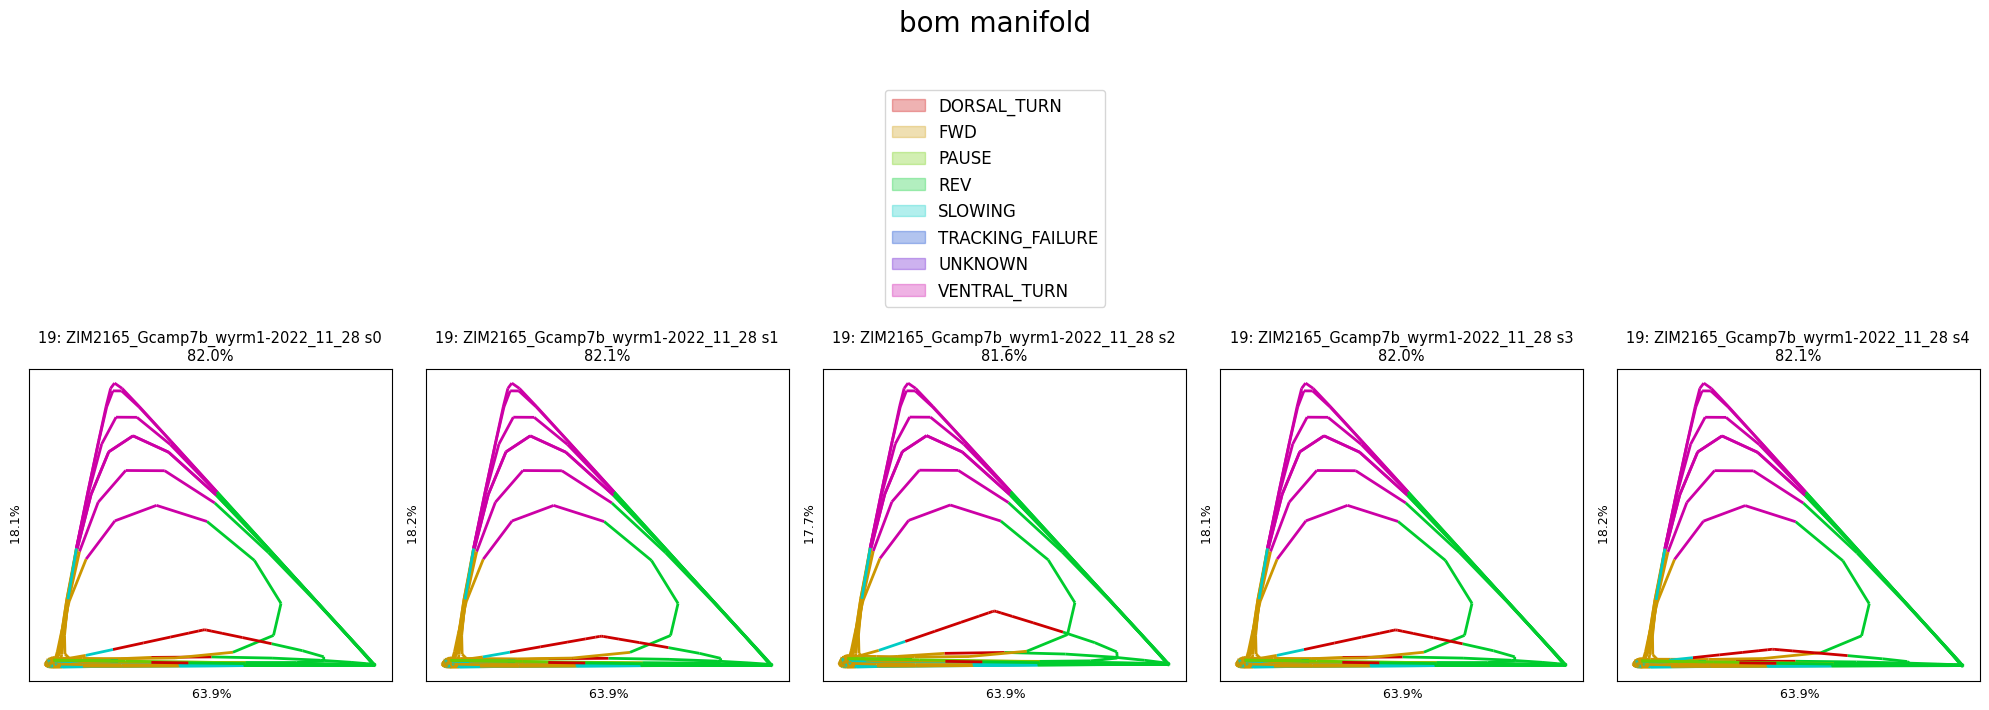

82.0%


In [10]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(bom_manifolds))],
						  [bom_manifolds[s] for s in range(len(bom_manifolds))],
						  [discrete_states for s in range(len(bom_manifolds))],
						  bom_manifold_vars_expl, None,
						  title='bom manifold', plots_per_row=len(bom_manifolds), top_space=3.5,
						  save_path=None)

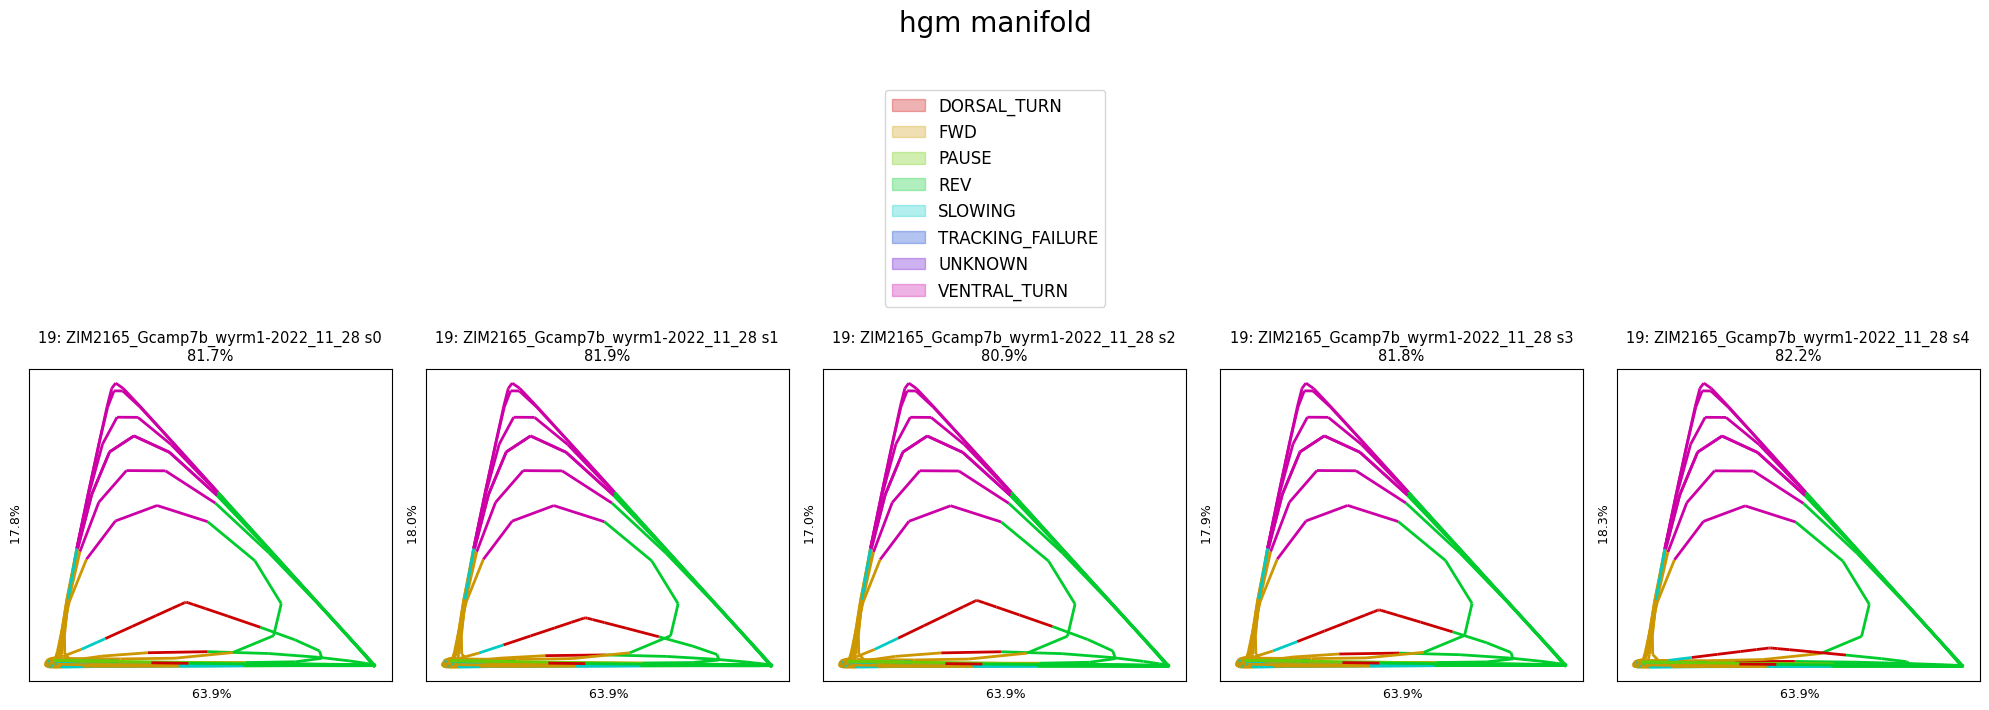

81.7%


In [11]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filename} s{s}' for s in range(len(hgm_manifolds))],
						  [hgm_manifolds[s] for s in range(len(hgm_manifolds))],
						  [discrete_states for s in range(len(hgm_manifolds))],
						  hgm_manifold_vars_expl, None,
						  title='hgm manifold', plots_per_row=len(hgm_manifolds), top_space=3.5,
						  save_path=None)

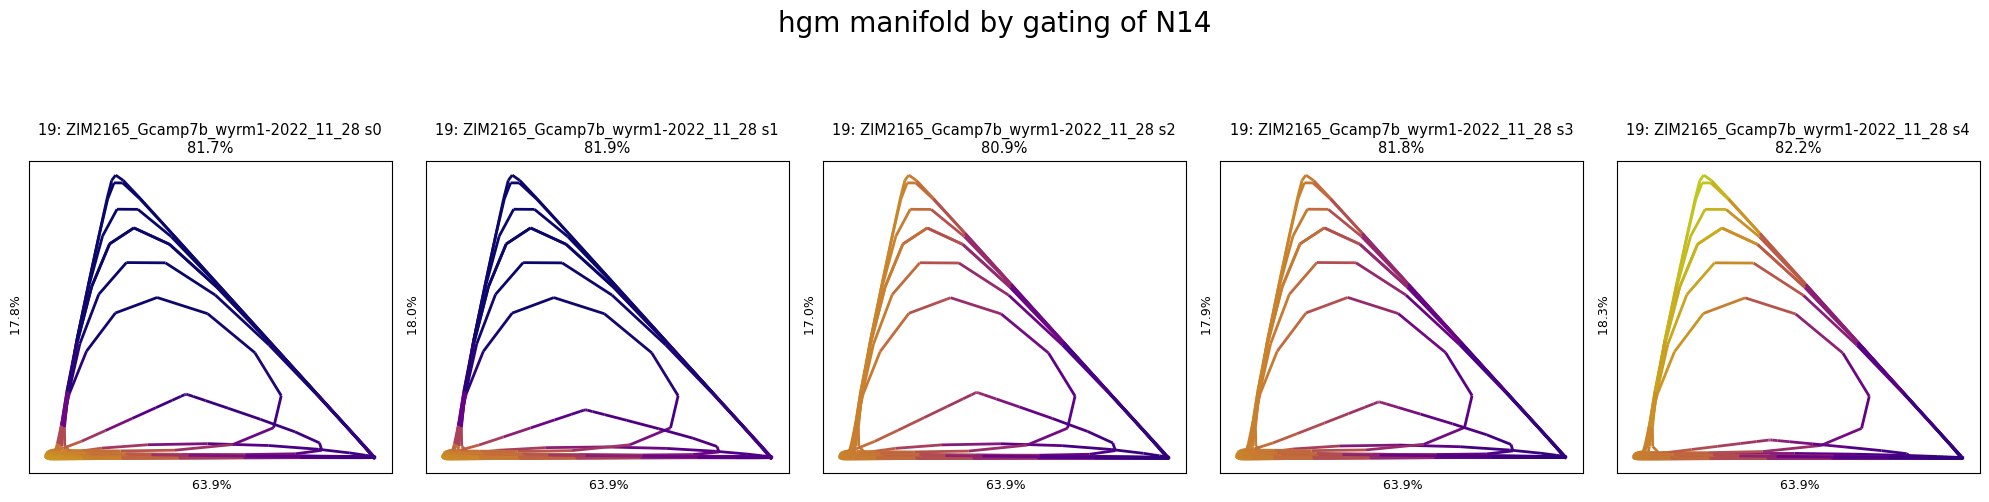

81.7%


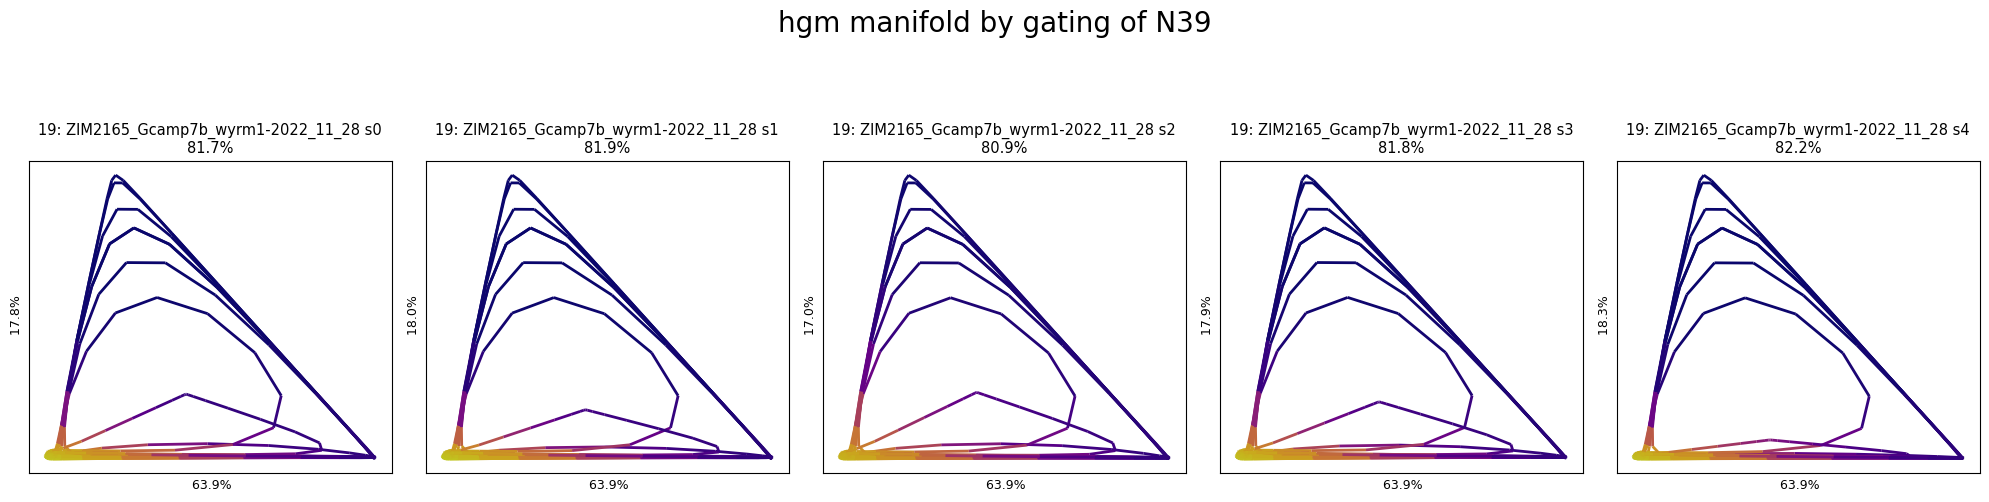

81.7%


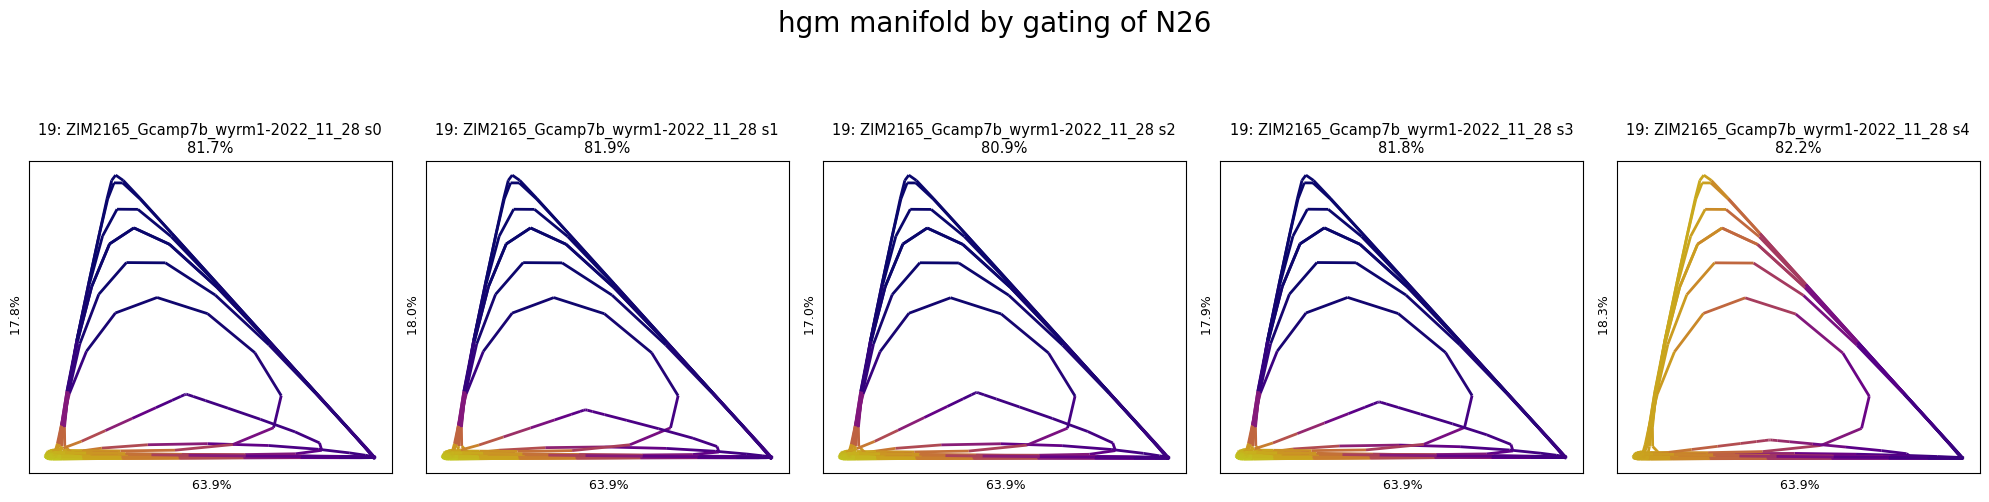

81.7%


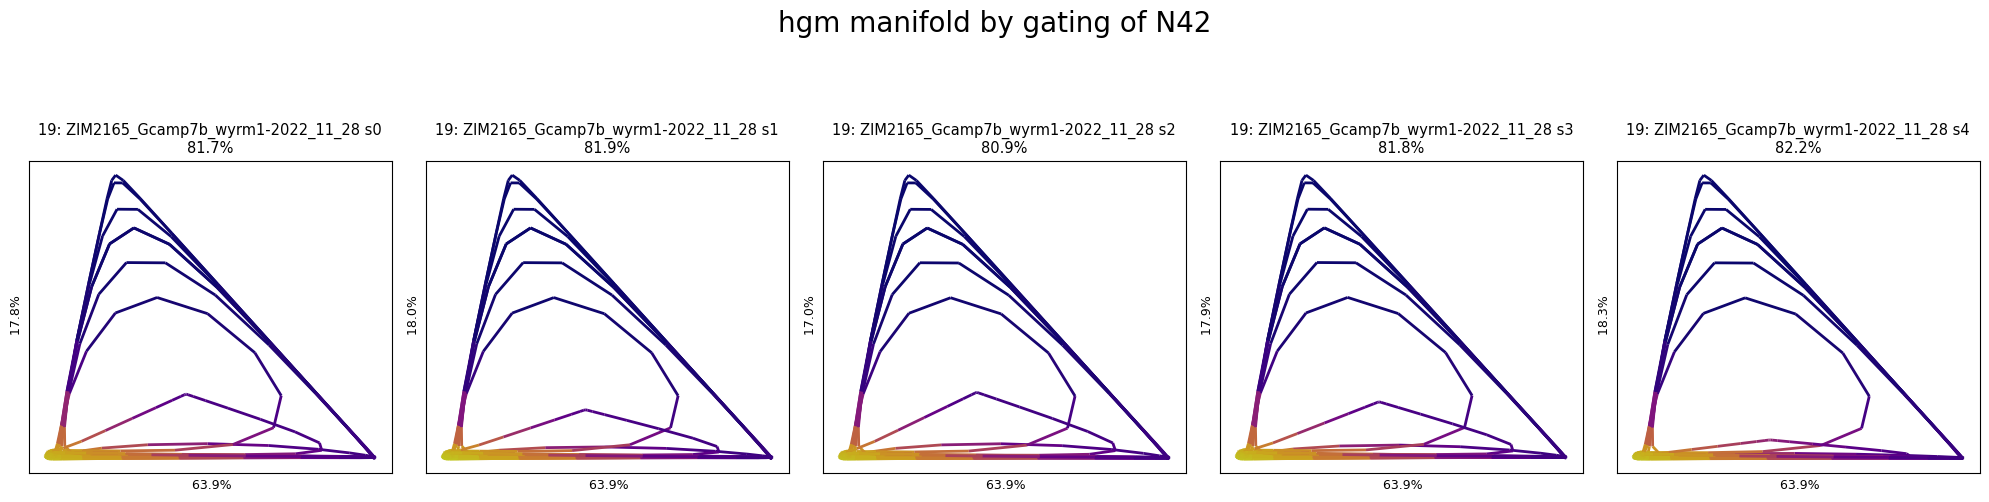

81.7%


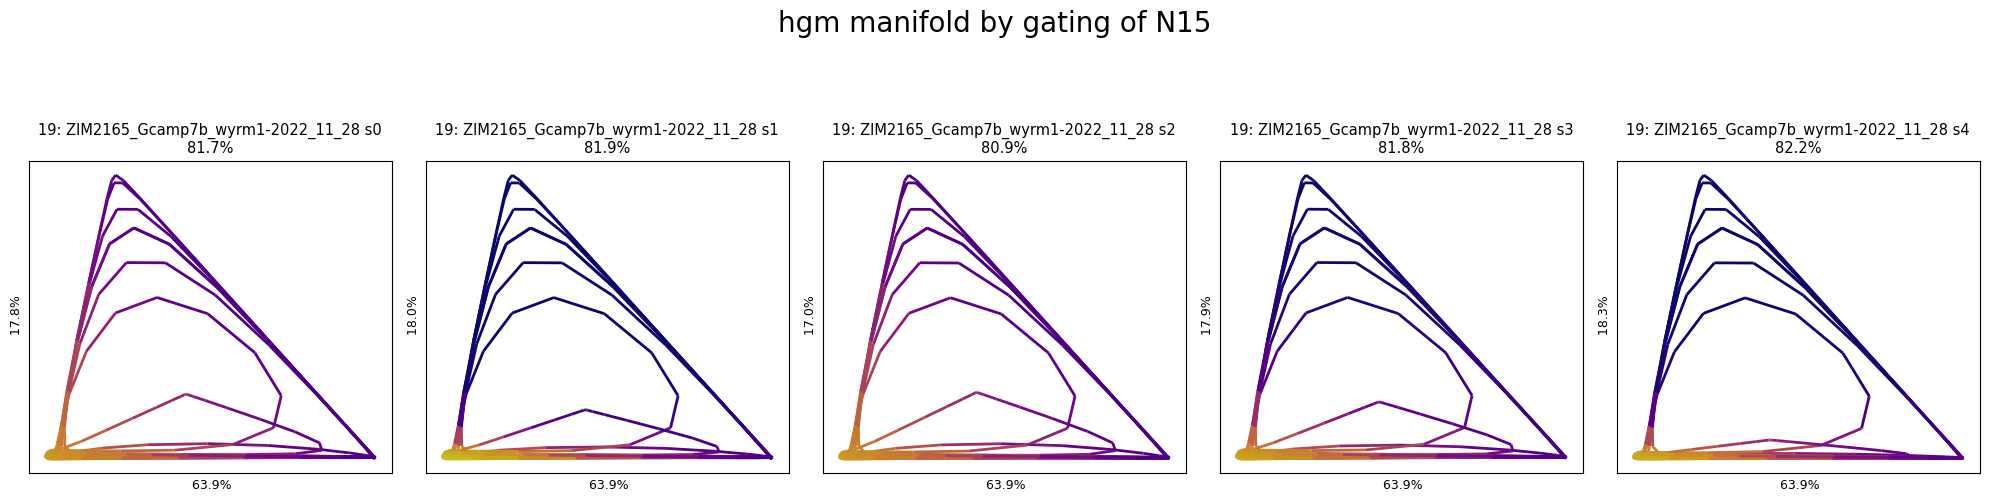

81.7%


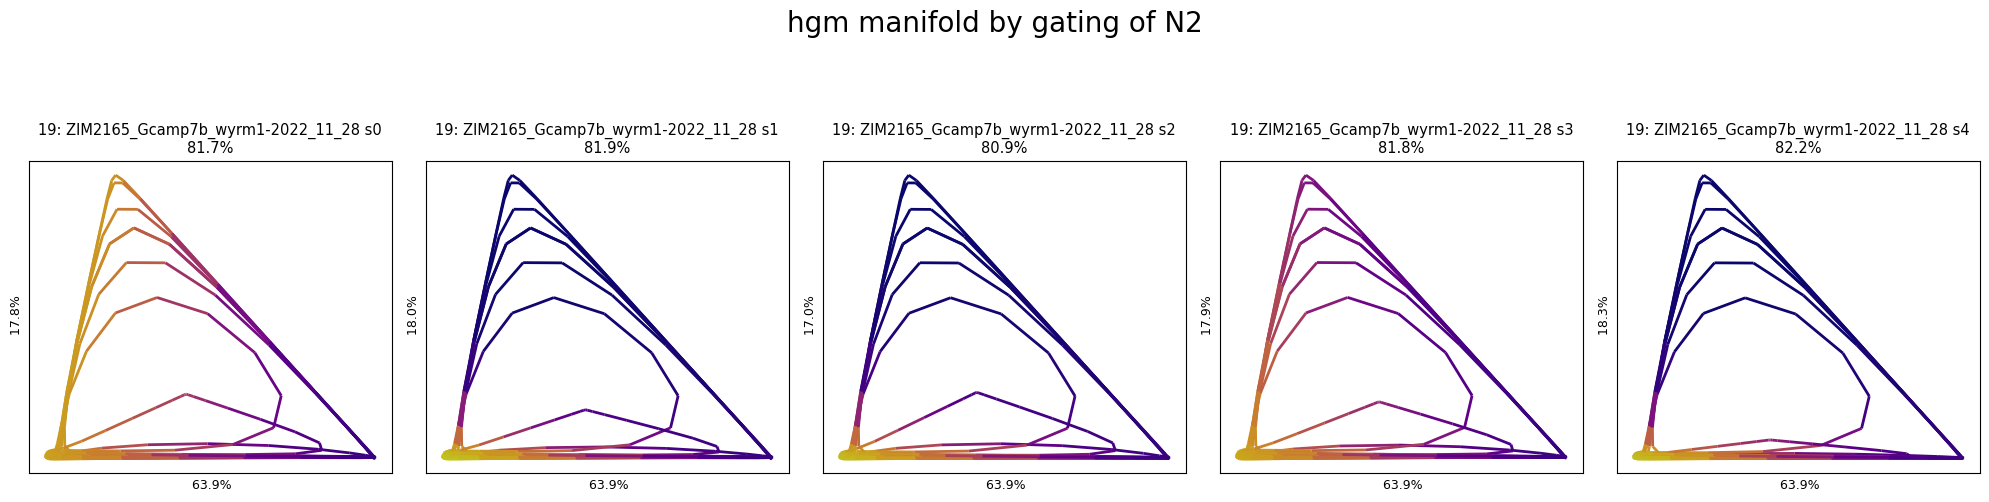

81.7%


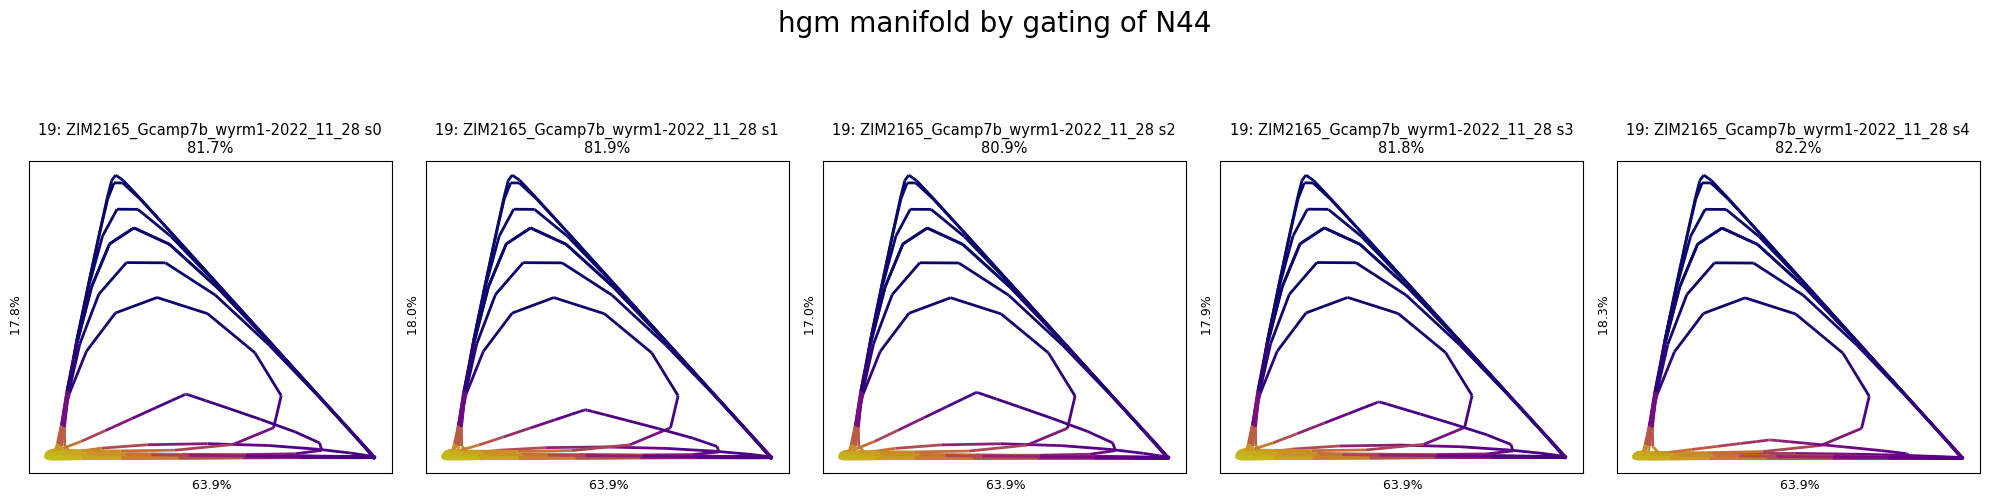

81.7%


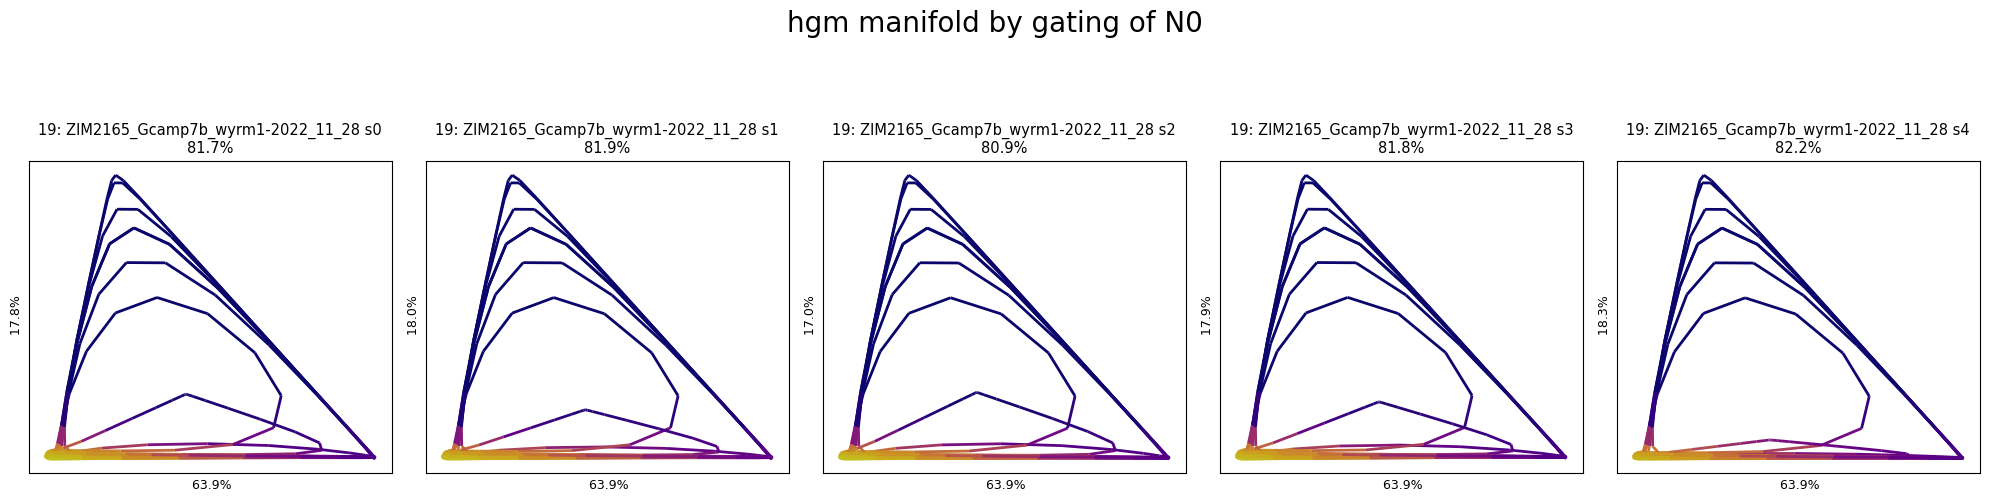

81.7%


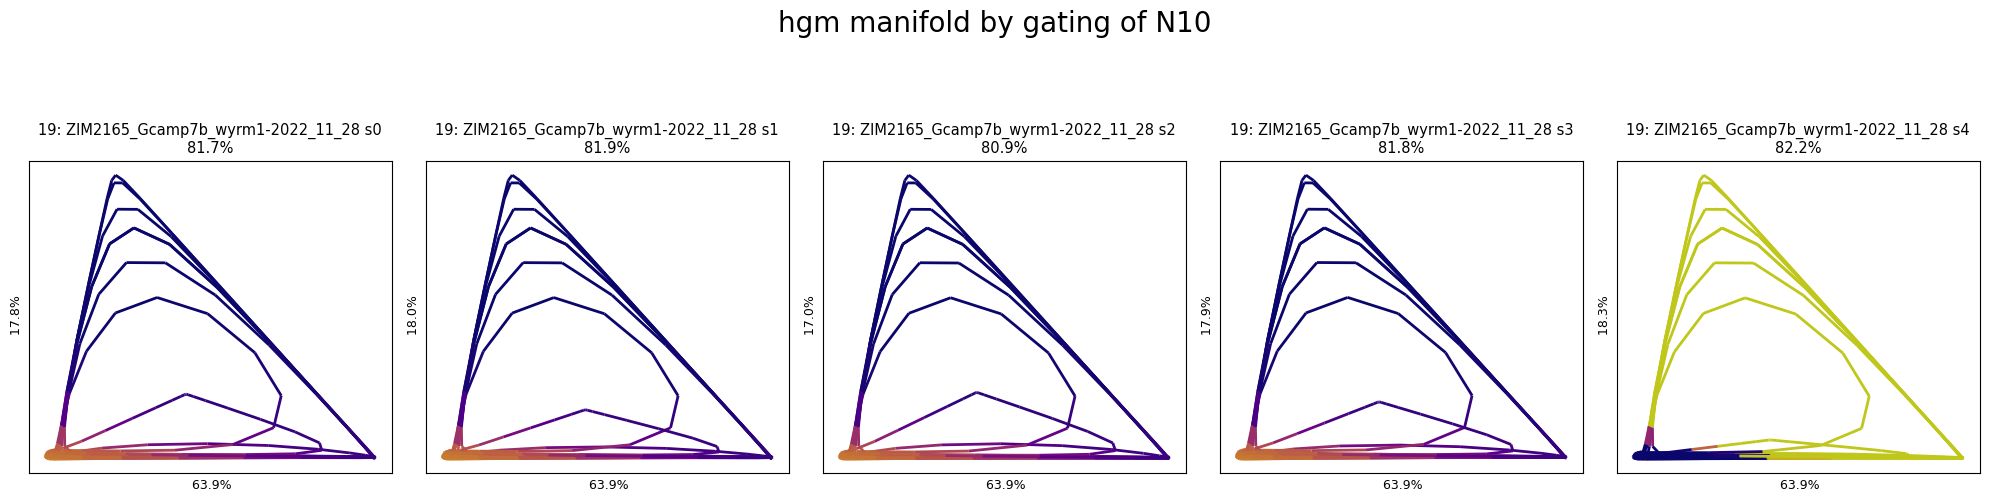

81.7%


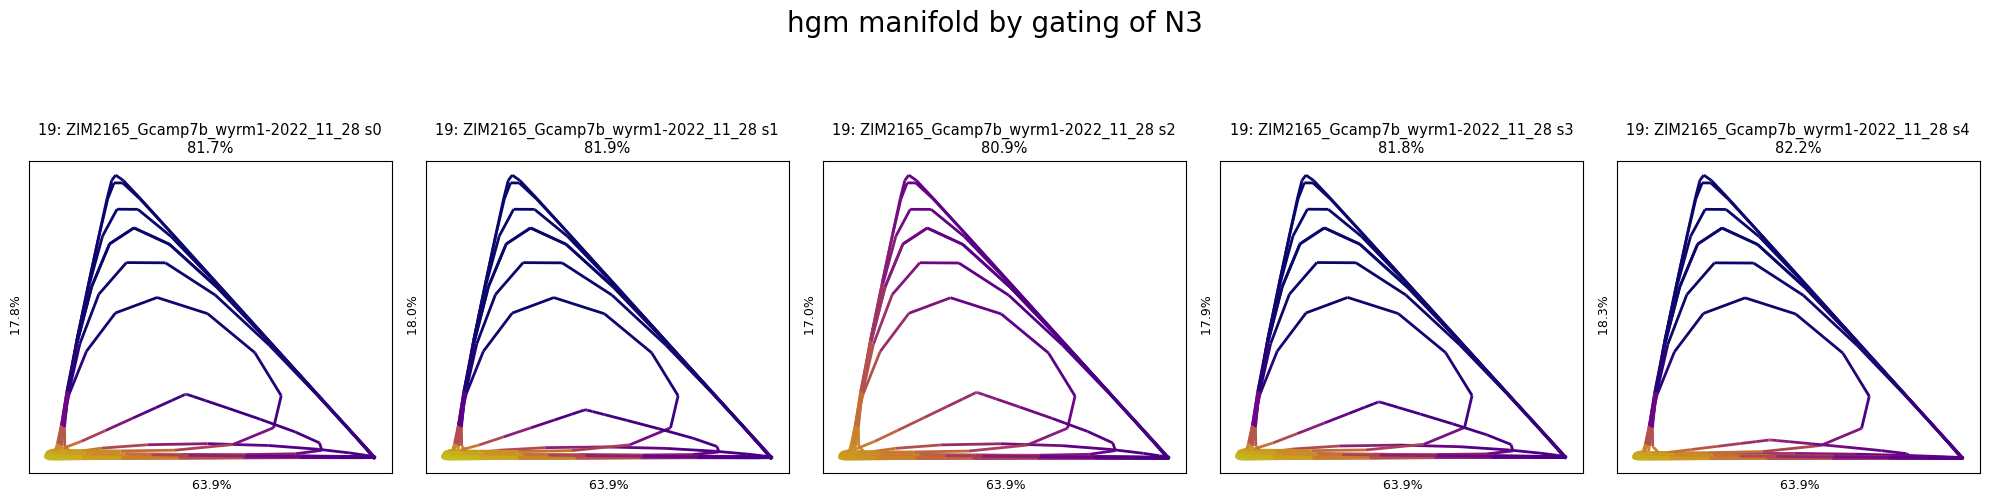

81.7%


In [12]:
sigmoid = lambda x: 1 / (1 + np.exp(-x))

neuron_ids = [traces.columns.get_loc(neuron) for neuron in neuron_labels]

splits = 5

for neuron_id in neuron_ids:
	sigmoid_terms = list()
	manifold_terms = list()
	vars_explained = list()
	for split in range(splits):
		hgm_man_zs = (hgm_man[split].values - hgm_man[split].values.mean(axis=0)) / np.where((N_std := hgm_man[split].values.std(axis=0)) == 0.0, 1.0, N_std)
		WM = hgm_params[split]['model']['WM'][:, neuron_id]
		sigmoid_term = sigmoid(hgm_man_zs @ WM)
		sigmoid_terms.append(pd.DataFrame(data=sigmoid_term))

		decode = lambda X: X @ model_utils.orthonormalize_qr(hgm_params[split]['model']['UN']).T
		manifold_term, var_explained = train_utils.postprocess_manifold(hgm_man[split].values, traces.values, decode, scale=False, align=True)
		manifold_terms.append(pd.DataFrame(data=manifold_term, columns=hgm_man[split].columns))
		vars_explained.append(var_explained)

	plot_utils.plot_manifolds_gradient([f'{str(file_id)}: {filename} s{s}' for s in range(splits)],
							  [manifold_terms[s] for s in range(splits)],
							  [sigmoid_terms[s] for s in range(splits)],
							  vars_explained, None,
							  title=f'hgm manifold by gating of {traces.columns[neuron_id]}', plots_per_row=splits, top_space=1,
							  save_path=None)

# traces

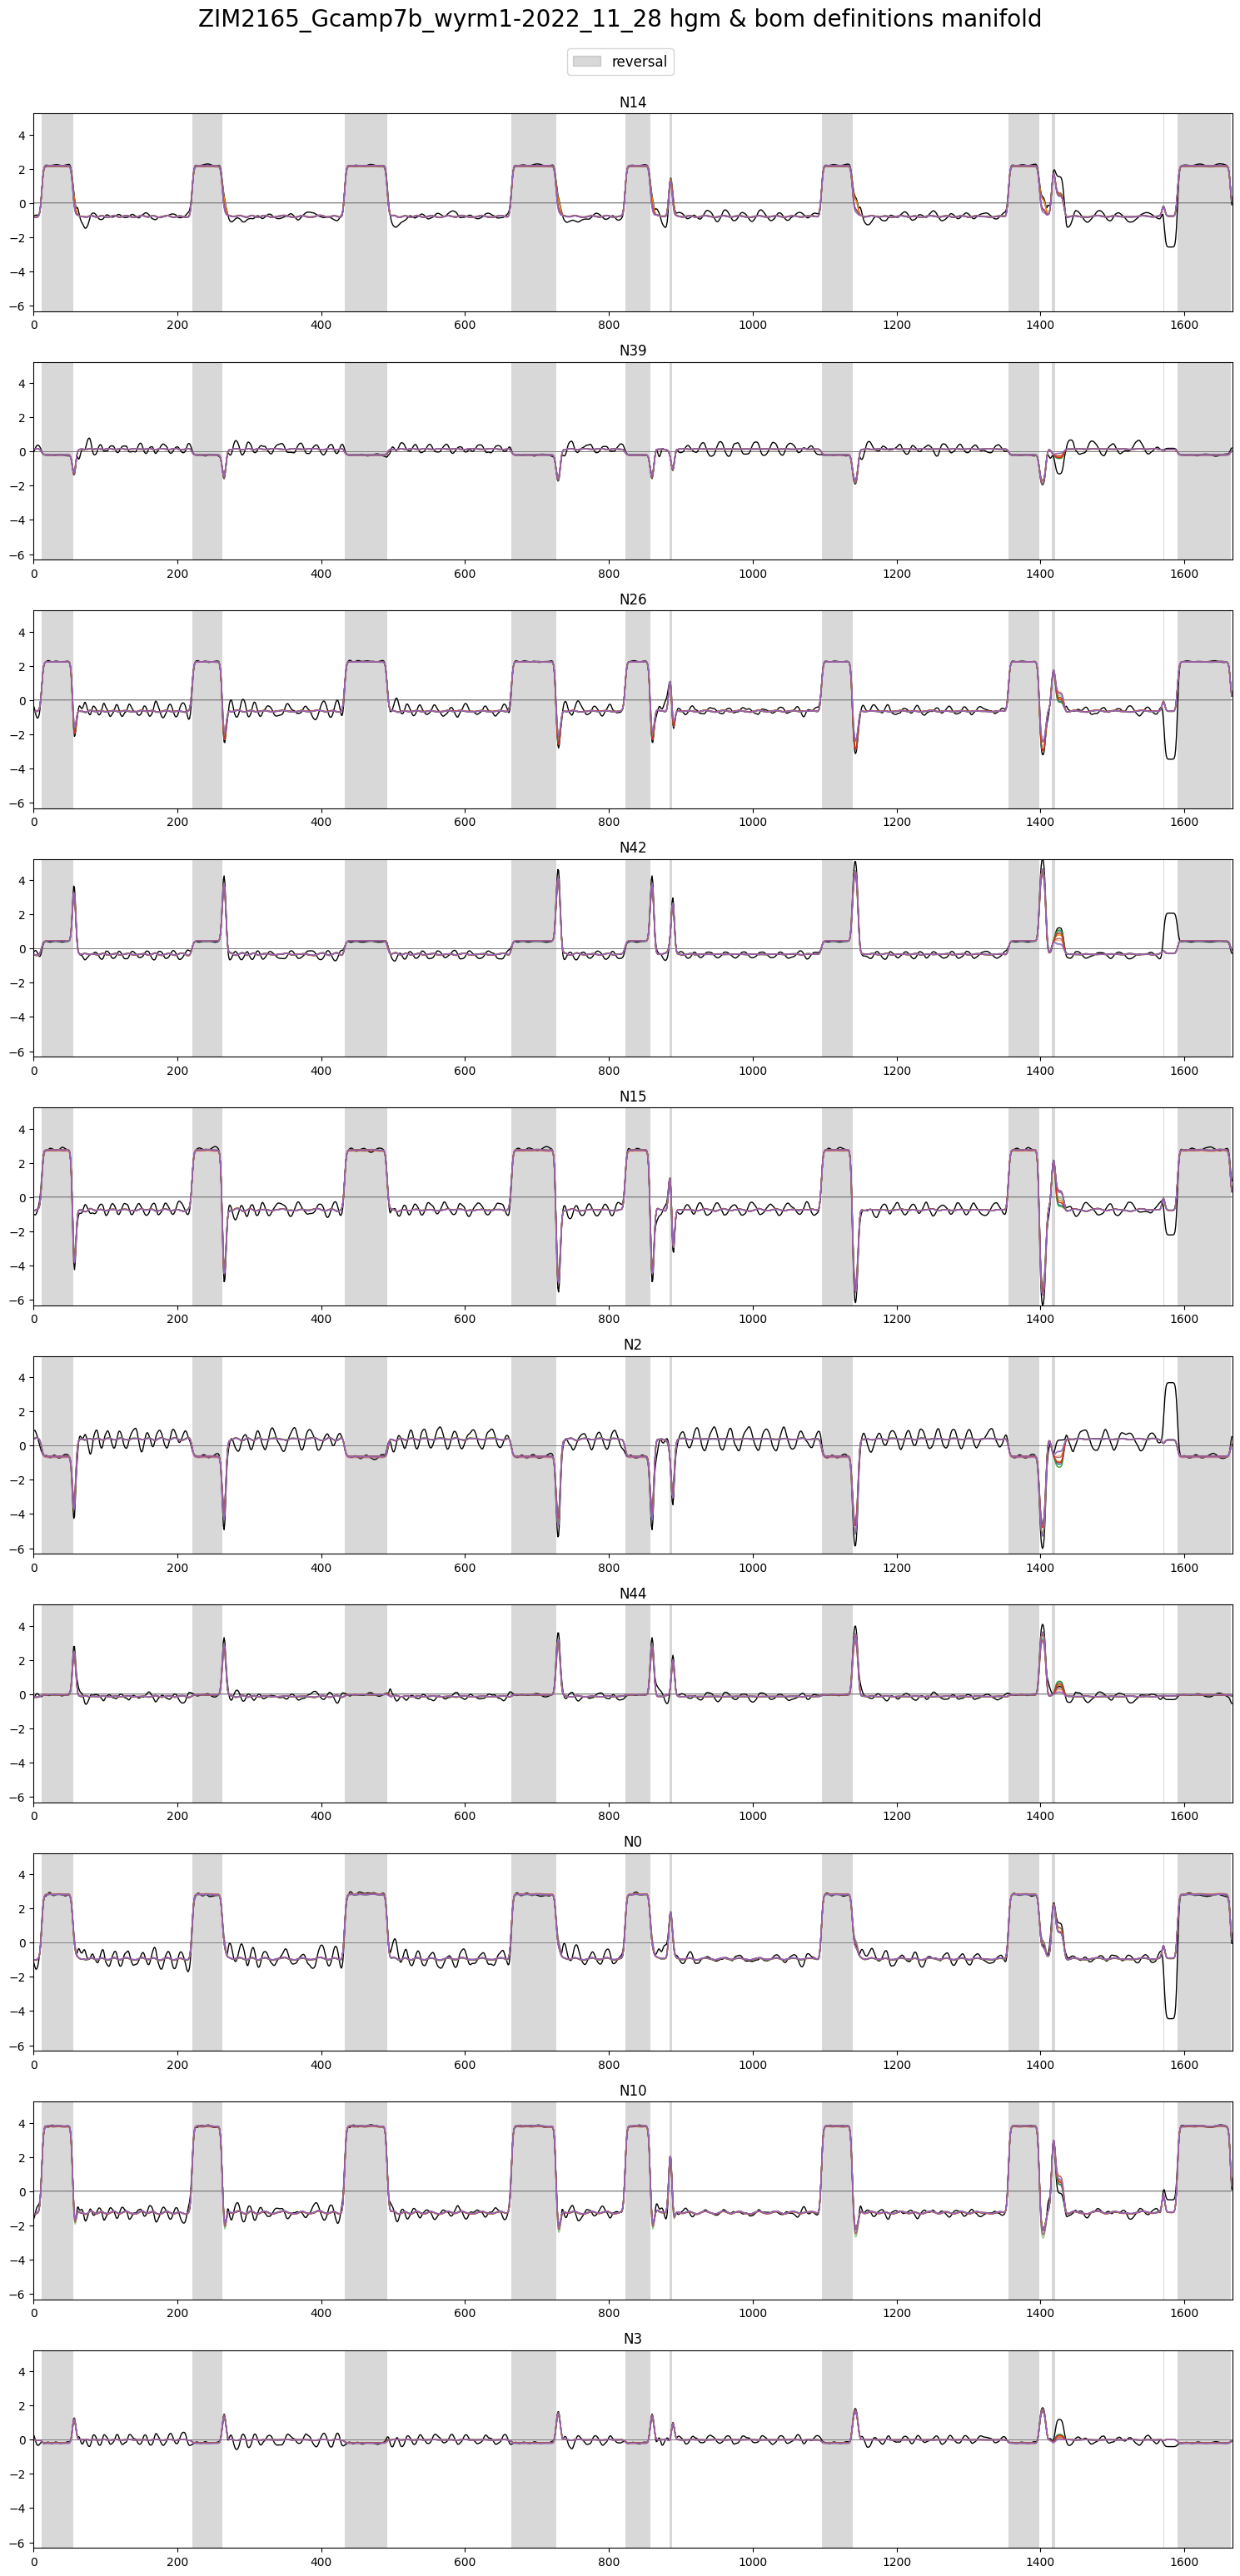

In [13]:
# max_x = 500
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_rec[i].loc[:max_x, neuron_labels] for i in range(len(hgm_rec))],
	[bom_rec[i].loc[:max_x, neuron_labels] for i in range(len(hgm_rec))],
	traces.loc[:max_x, neuron_labels],
	discrete_states.loc[:max_x, ['REV']], label='reversal',
	title=f'{filename} hgm & bom definitions manifold', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_MAN'

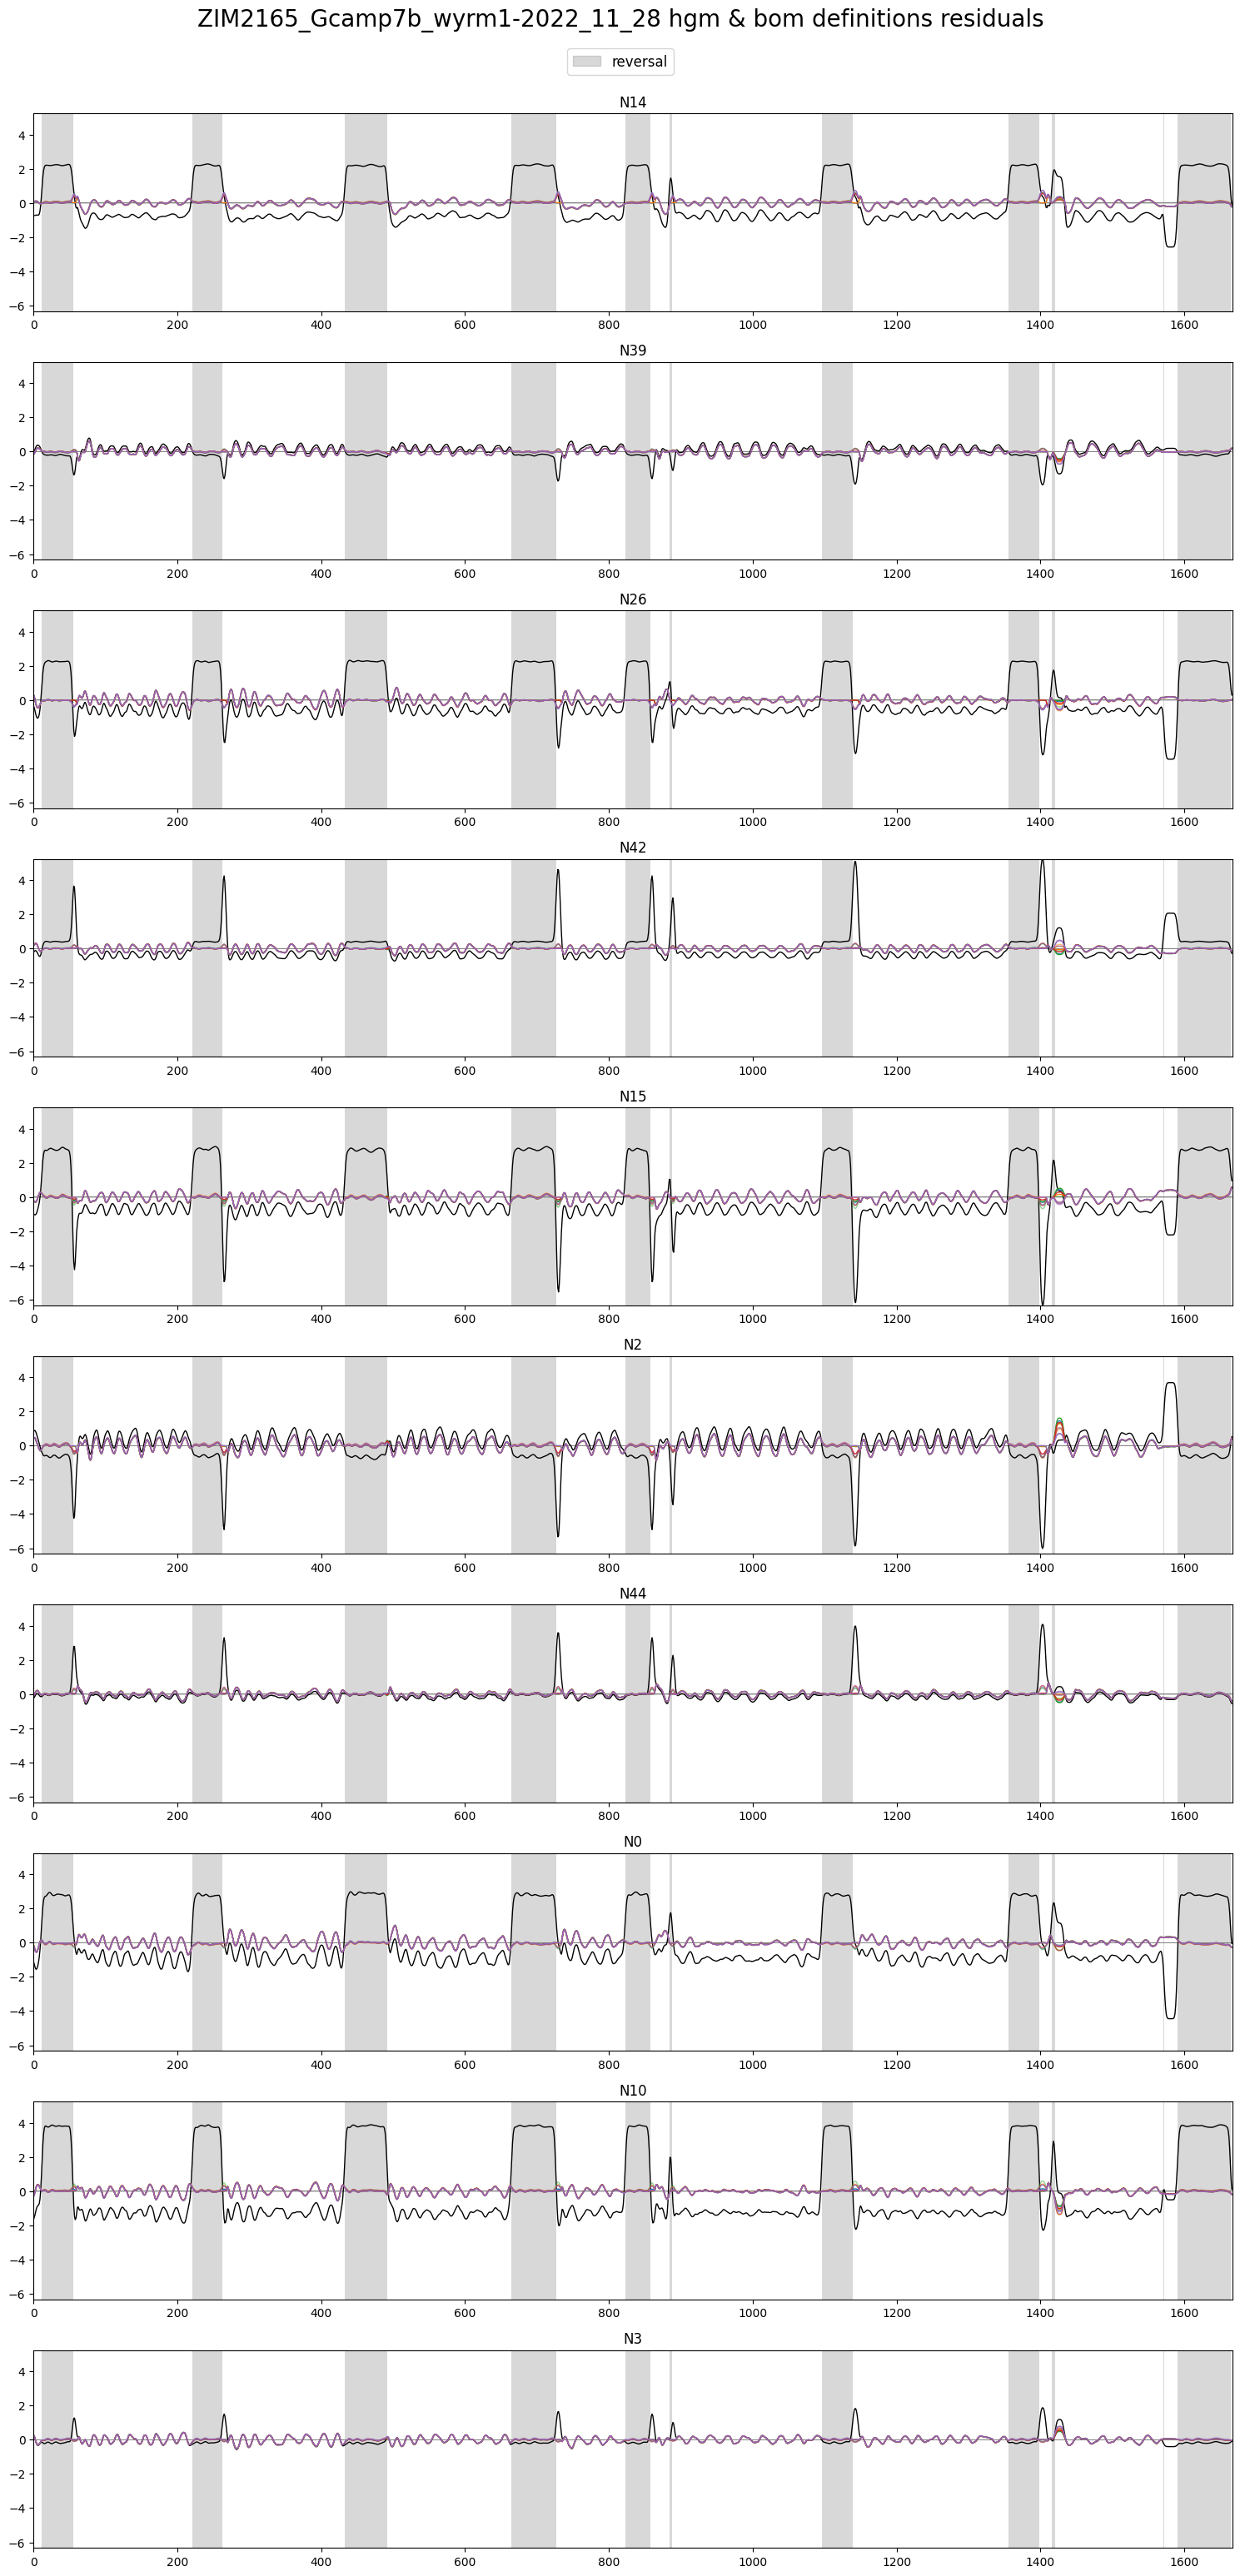

In [14]:
# max_x = 500
max_x = traces.values.shape[0]

plot_utils.plot_traces_splits(
	[hgm_res[i].loc[:max_x, neuron_labels] for i in range(splits)],
	[bom_res[i].loc[:max_x, neuron_labels] for i in range(splits)],
	traces.loc[:max_x, neuron_labels],
	discrete_states.loc[:max_x, ['REV']], label='reversal',
	title=f'{filename} hgm & bom definitions residuals', ylimits=None, plots_per_row=1,
	save_path=None)  #'../../out/plots/GCAMP_RES'

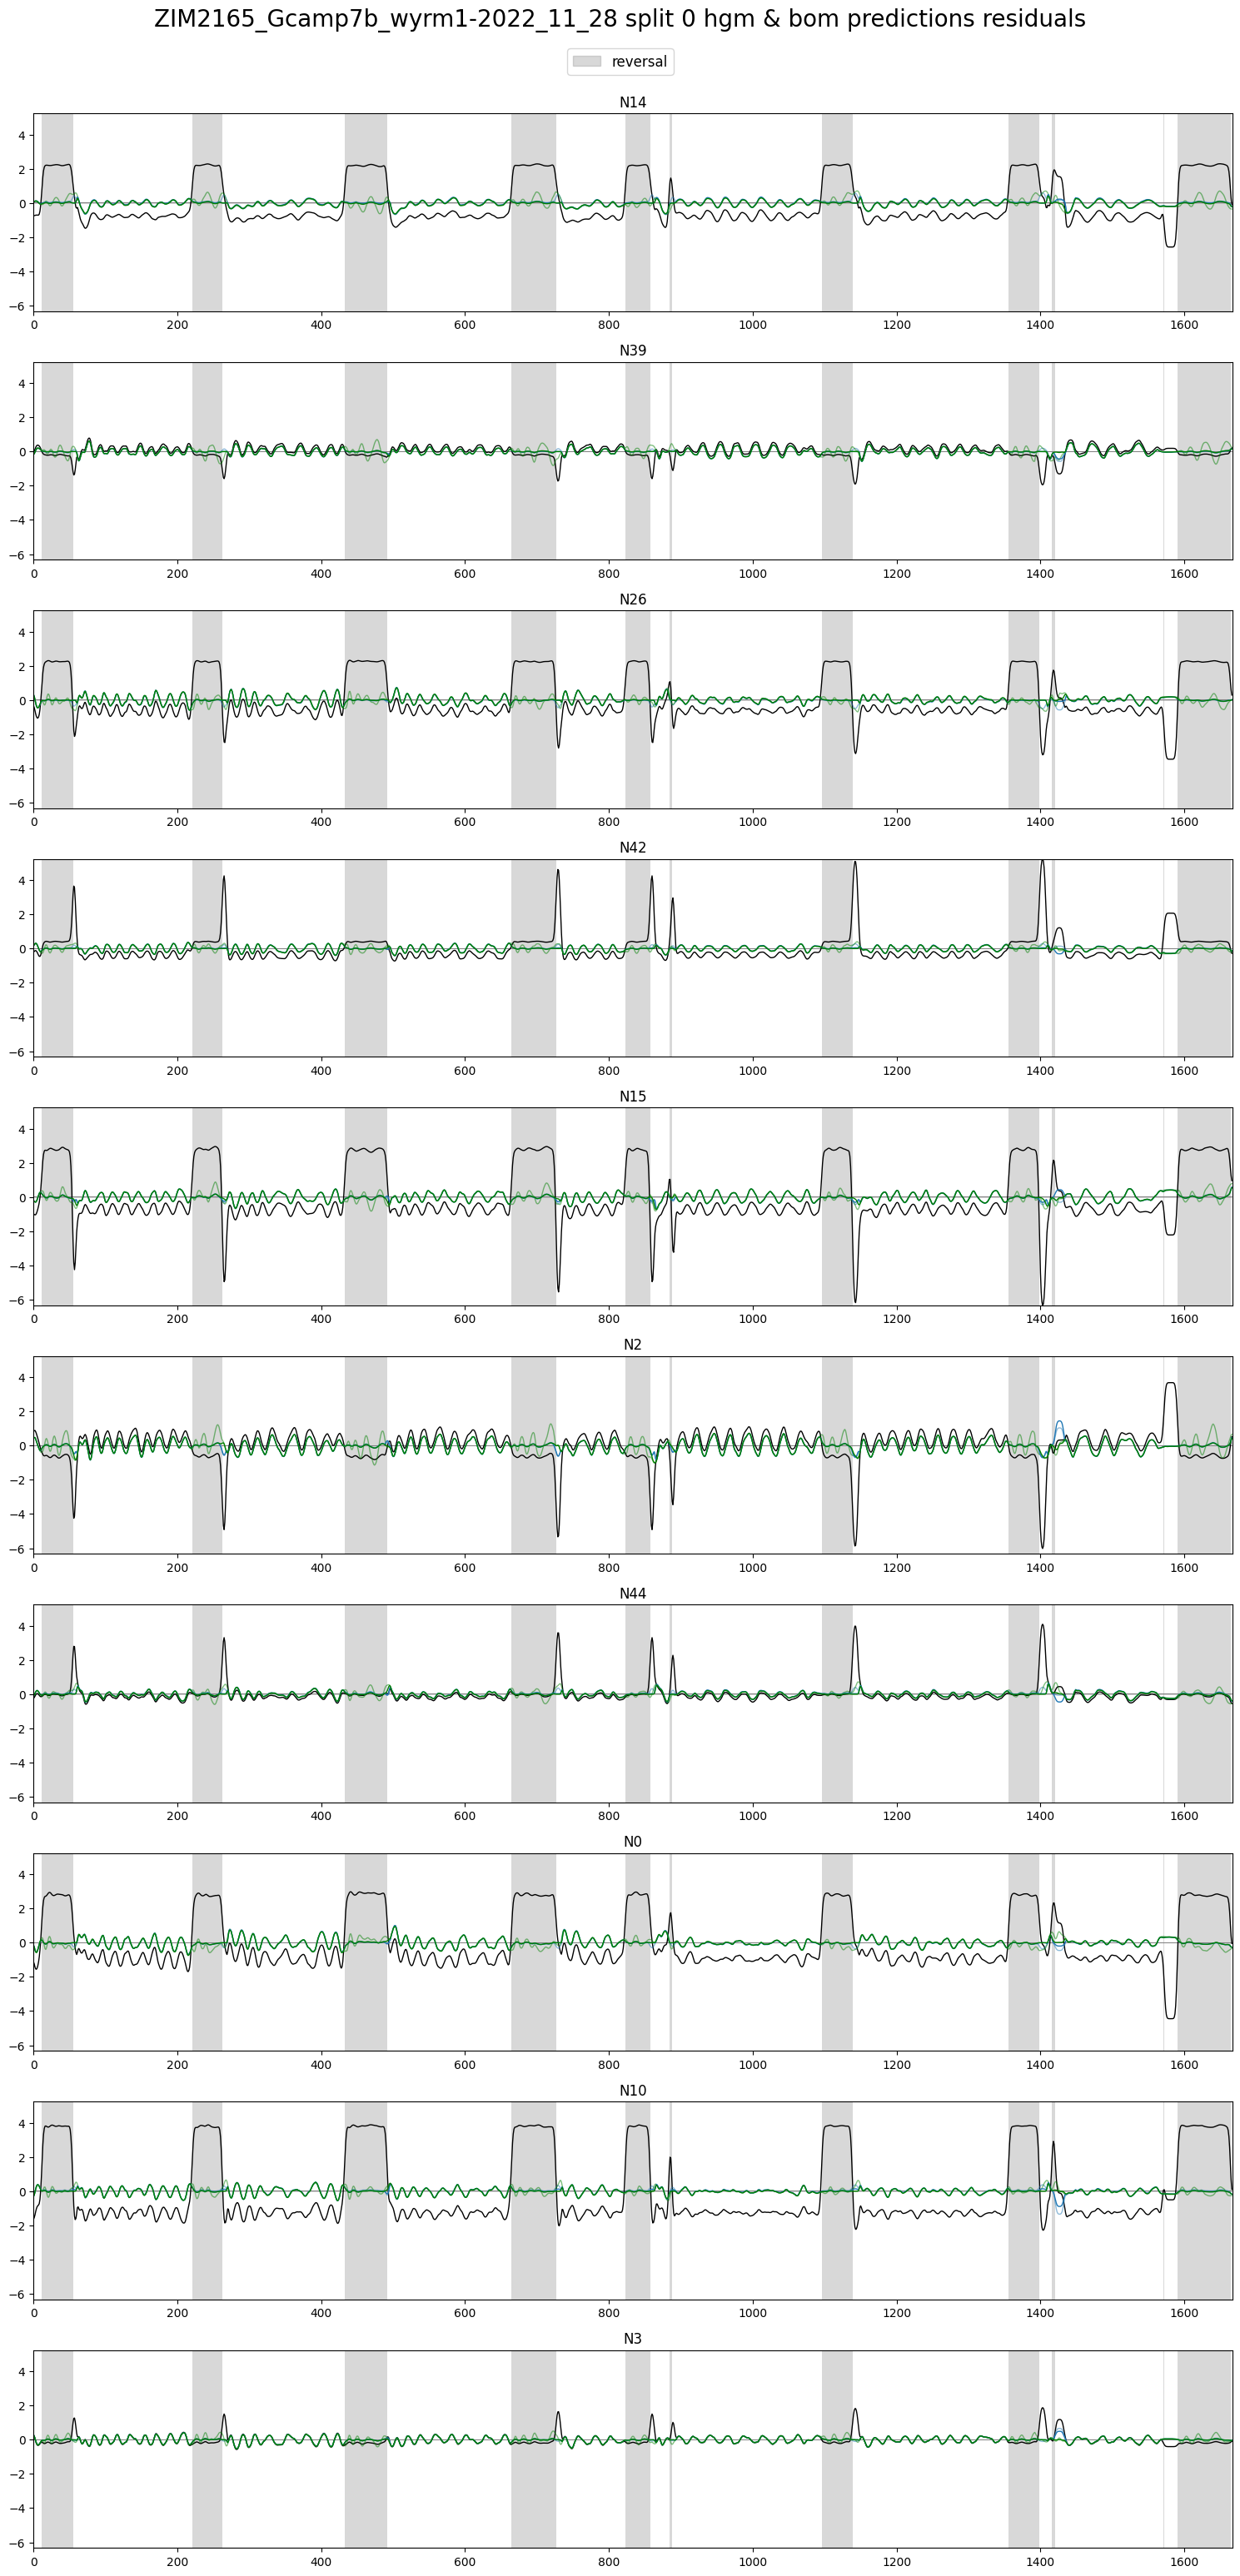

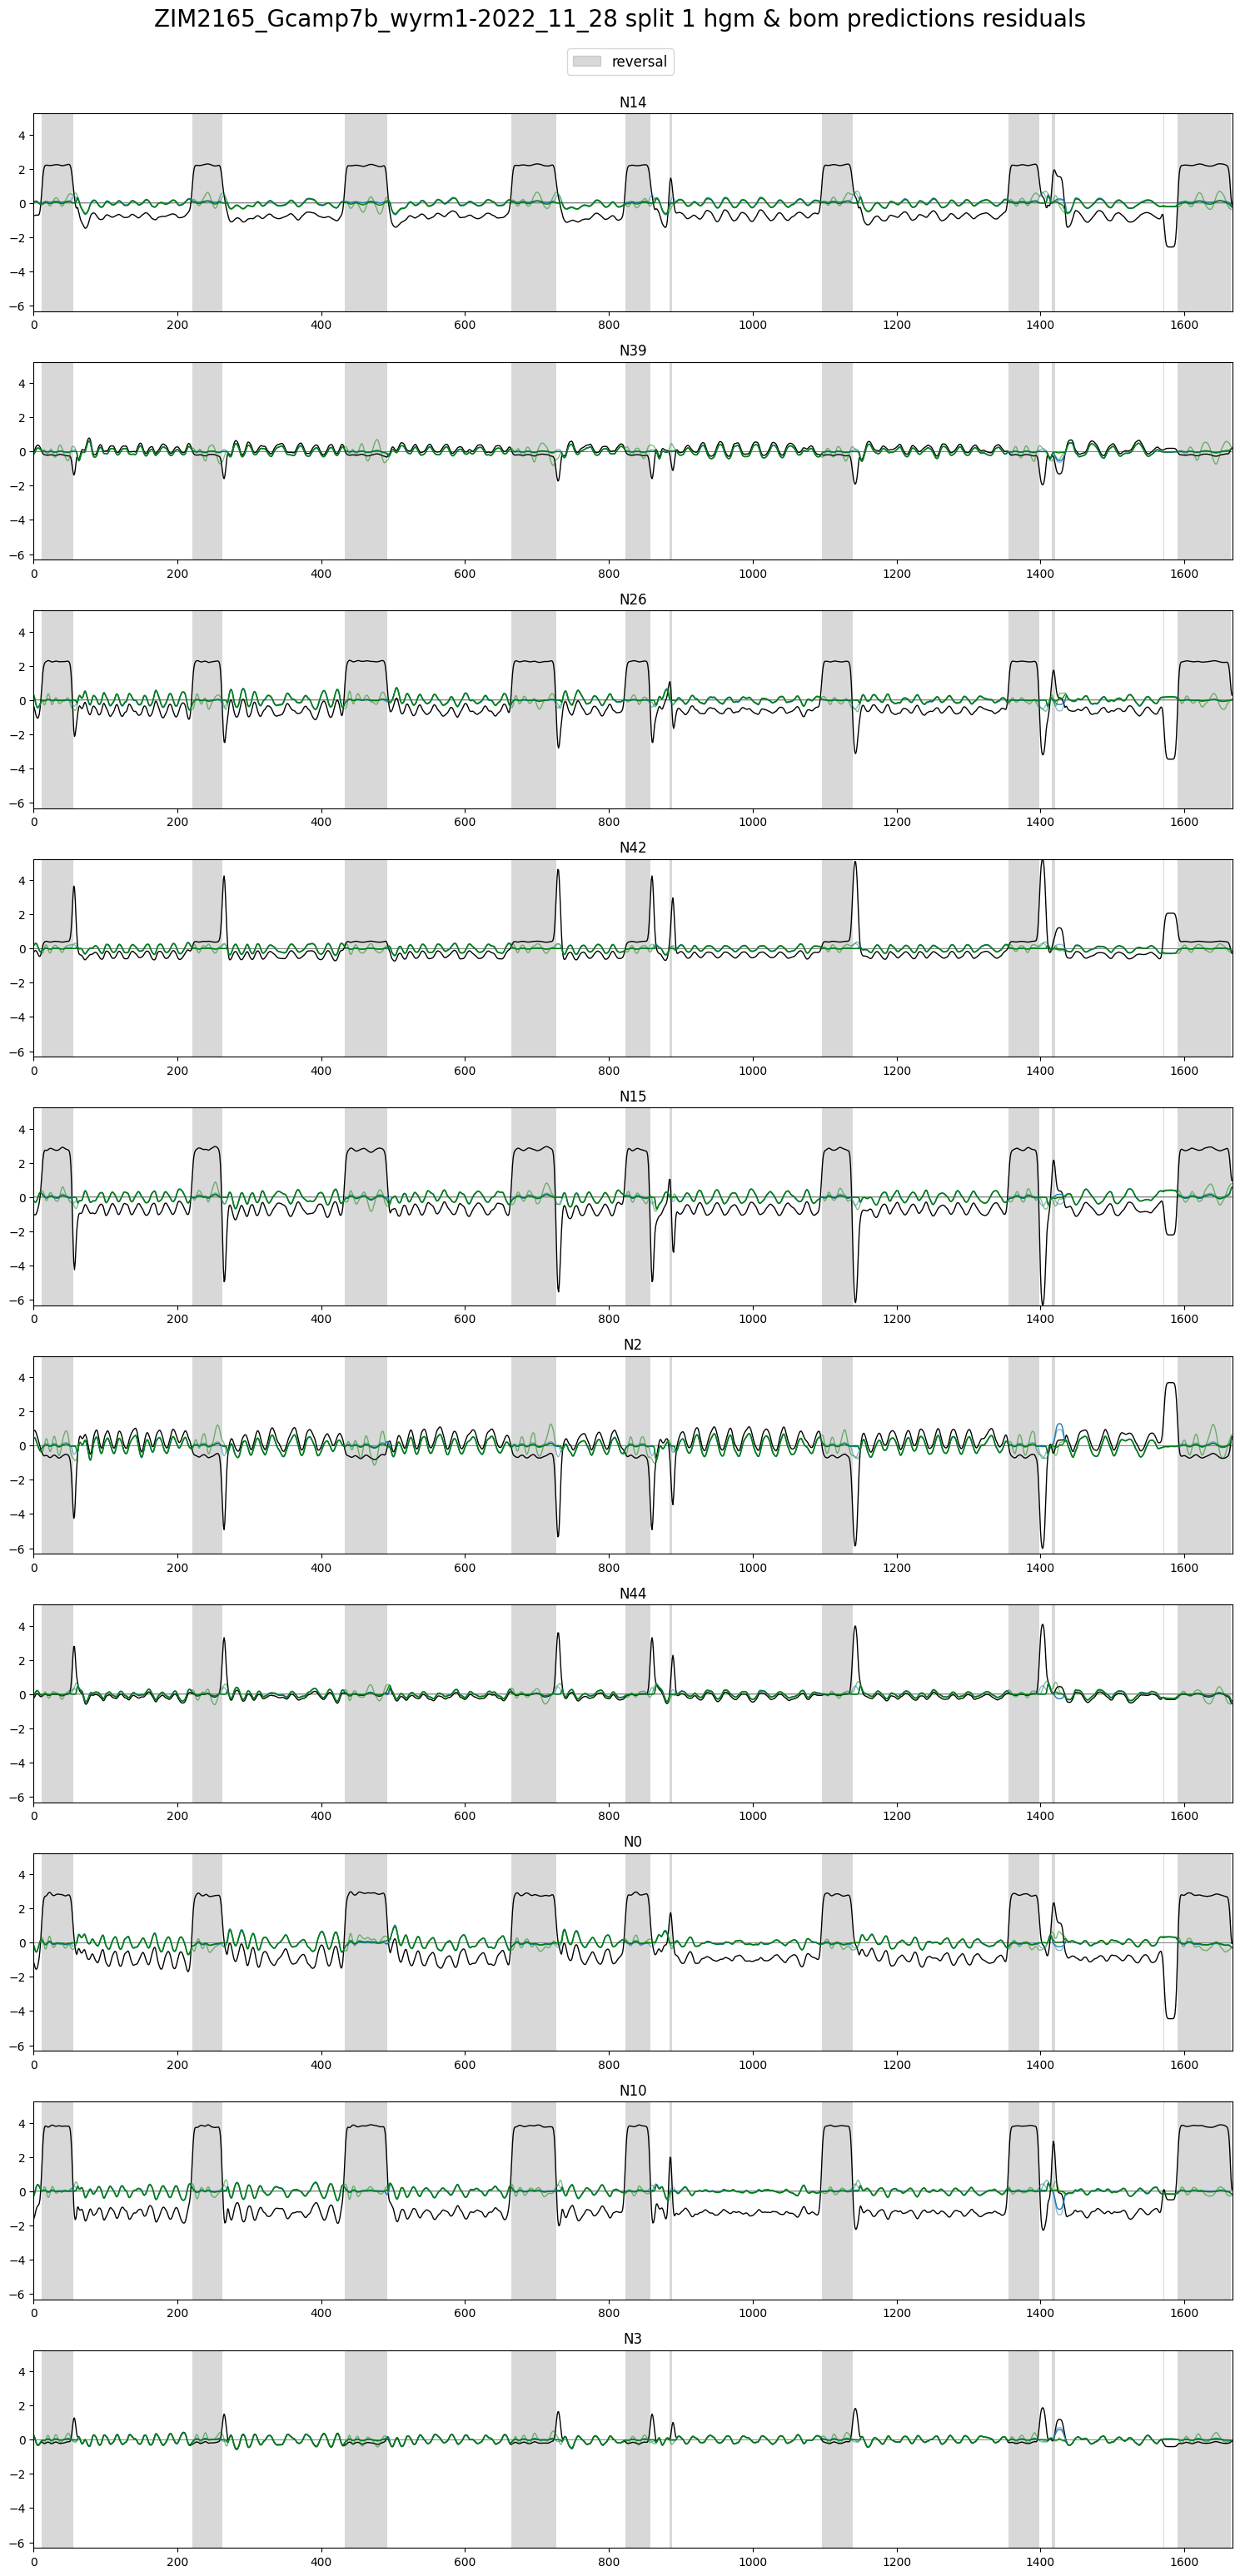

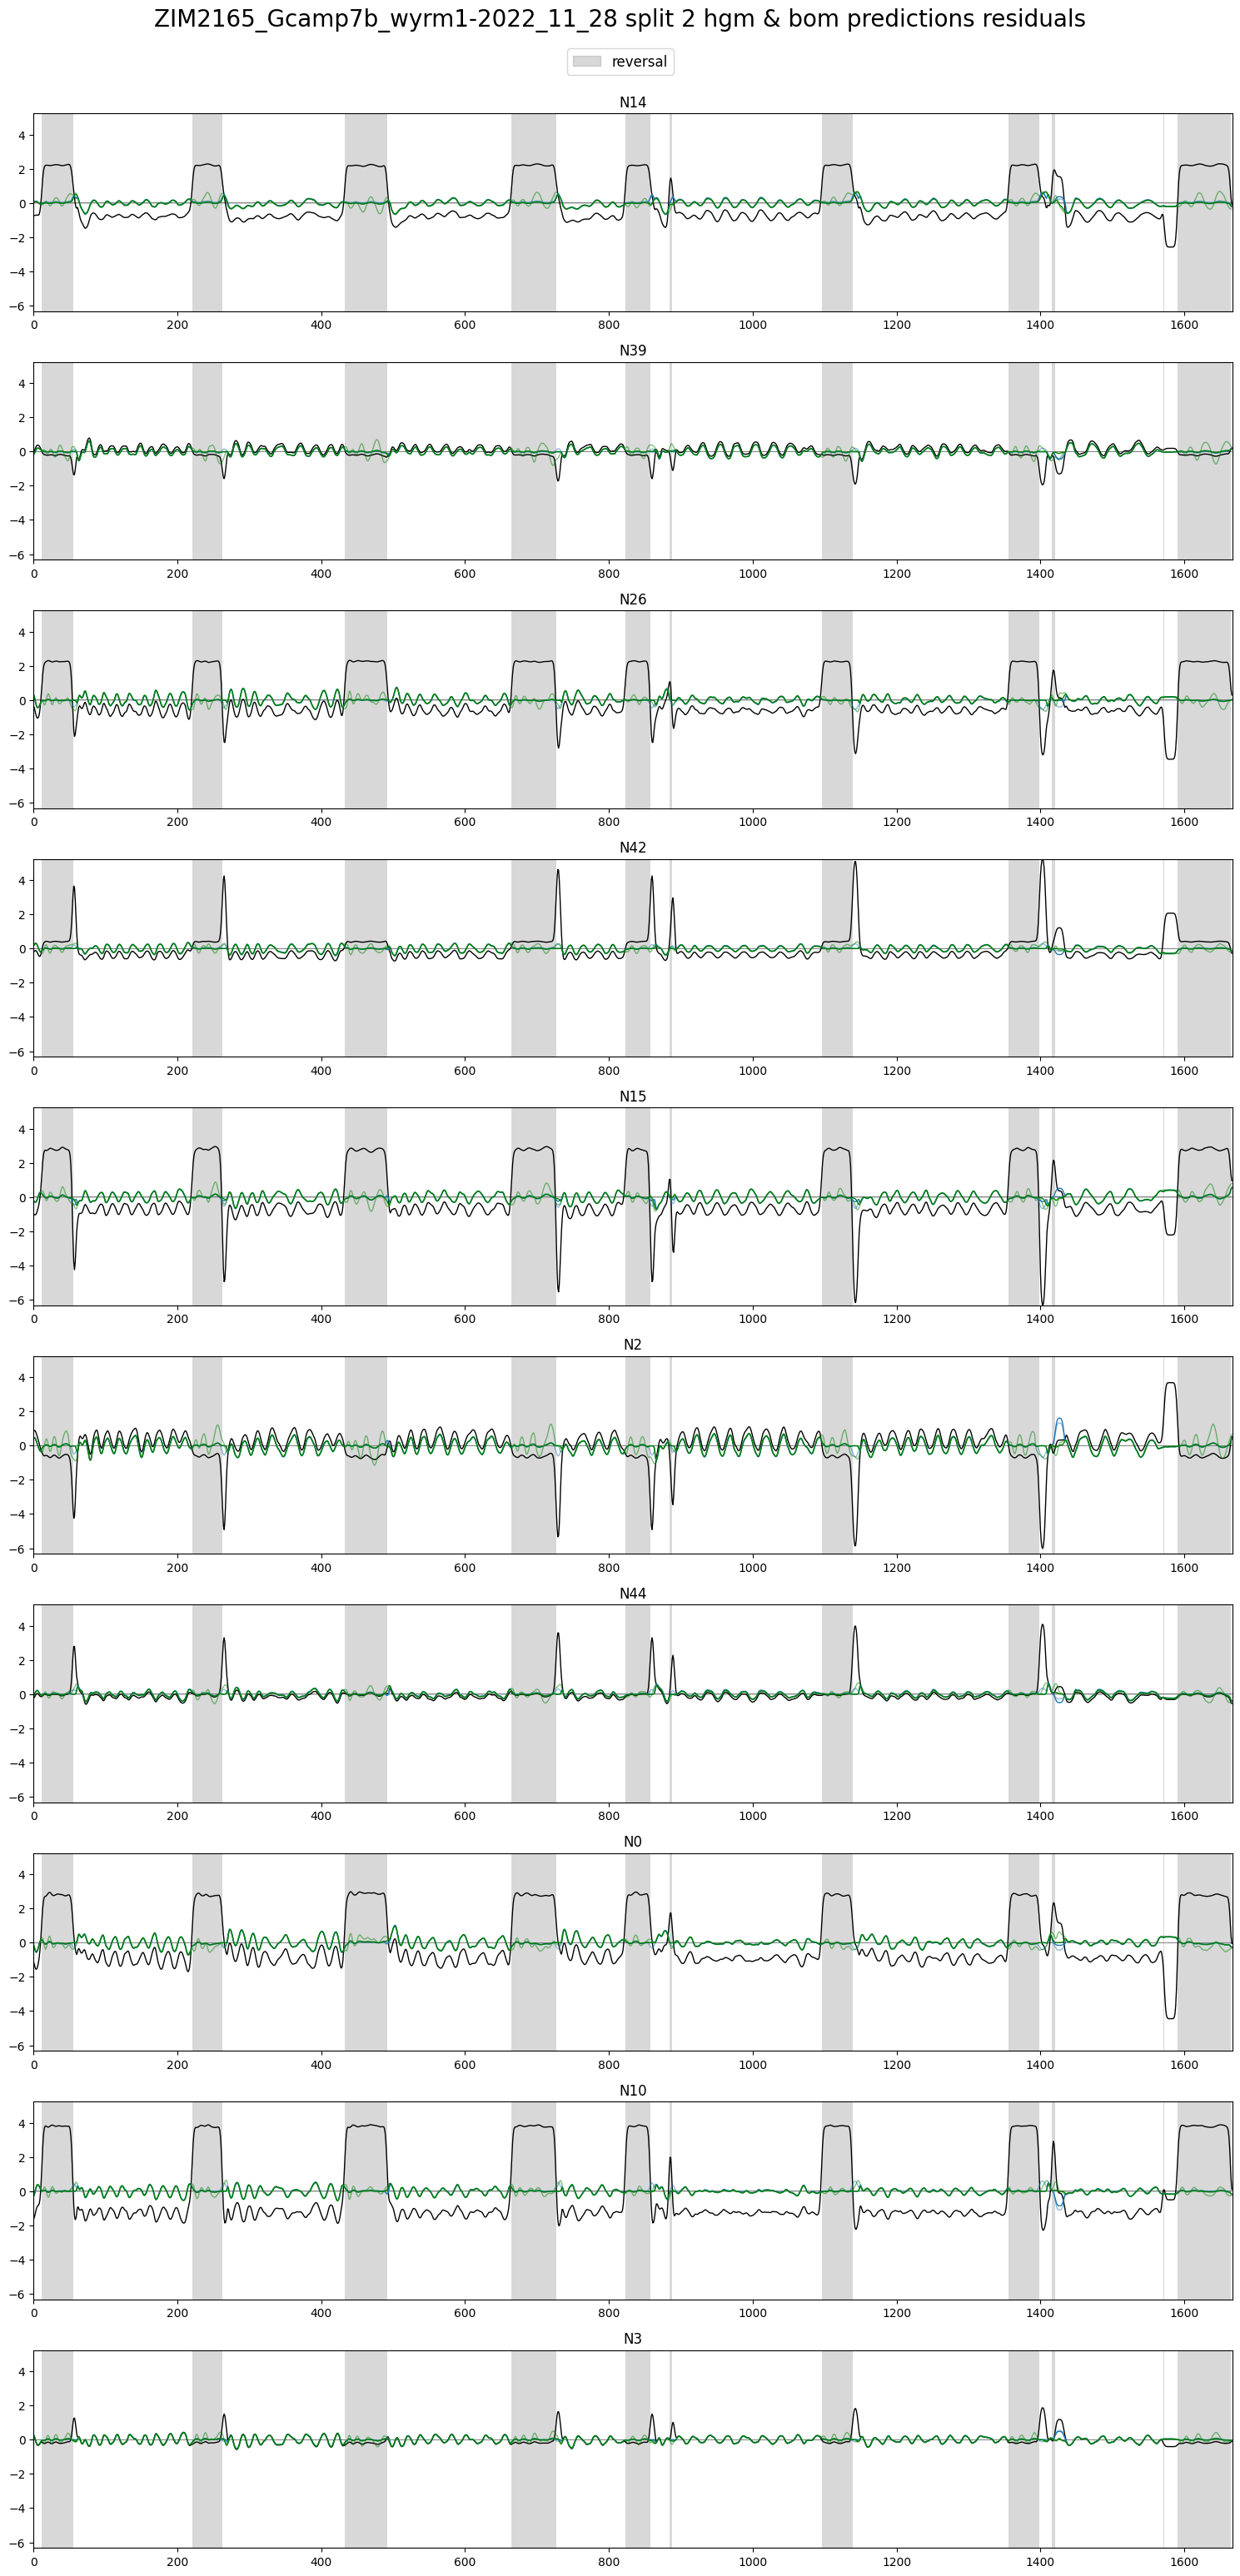

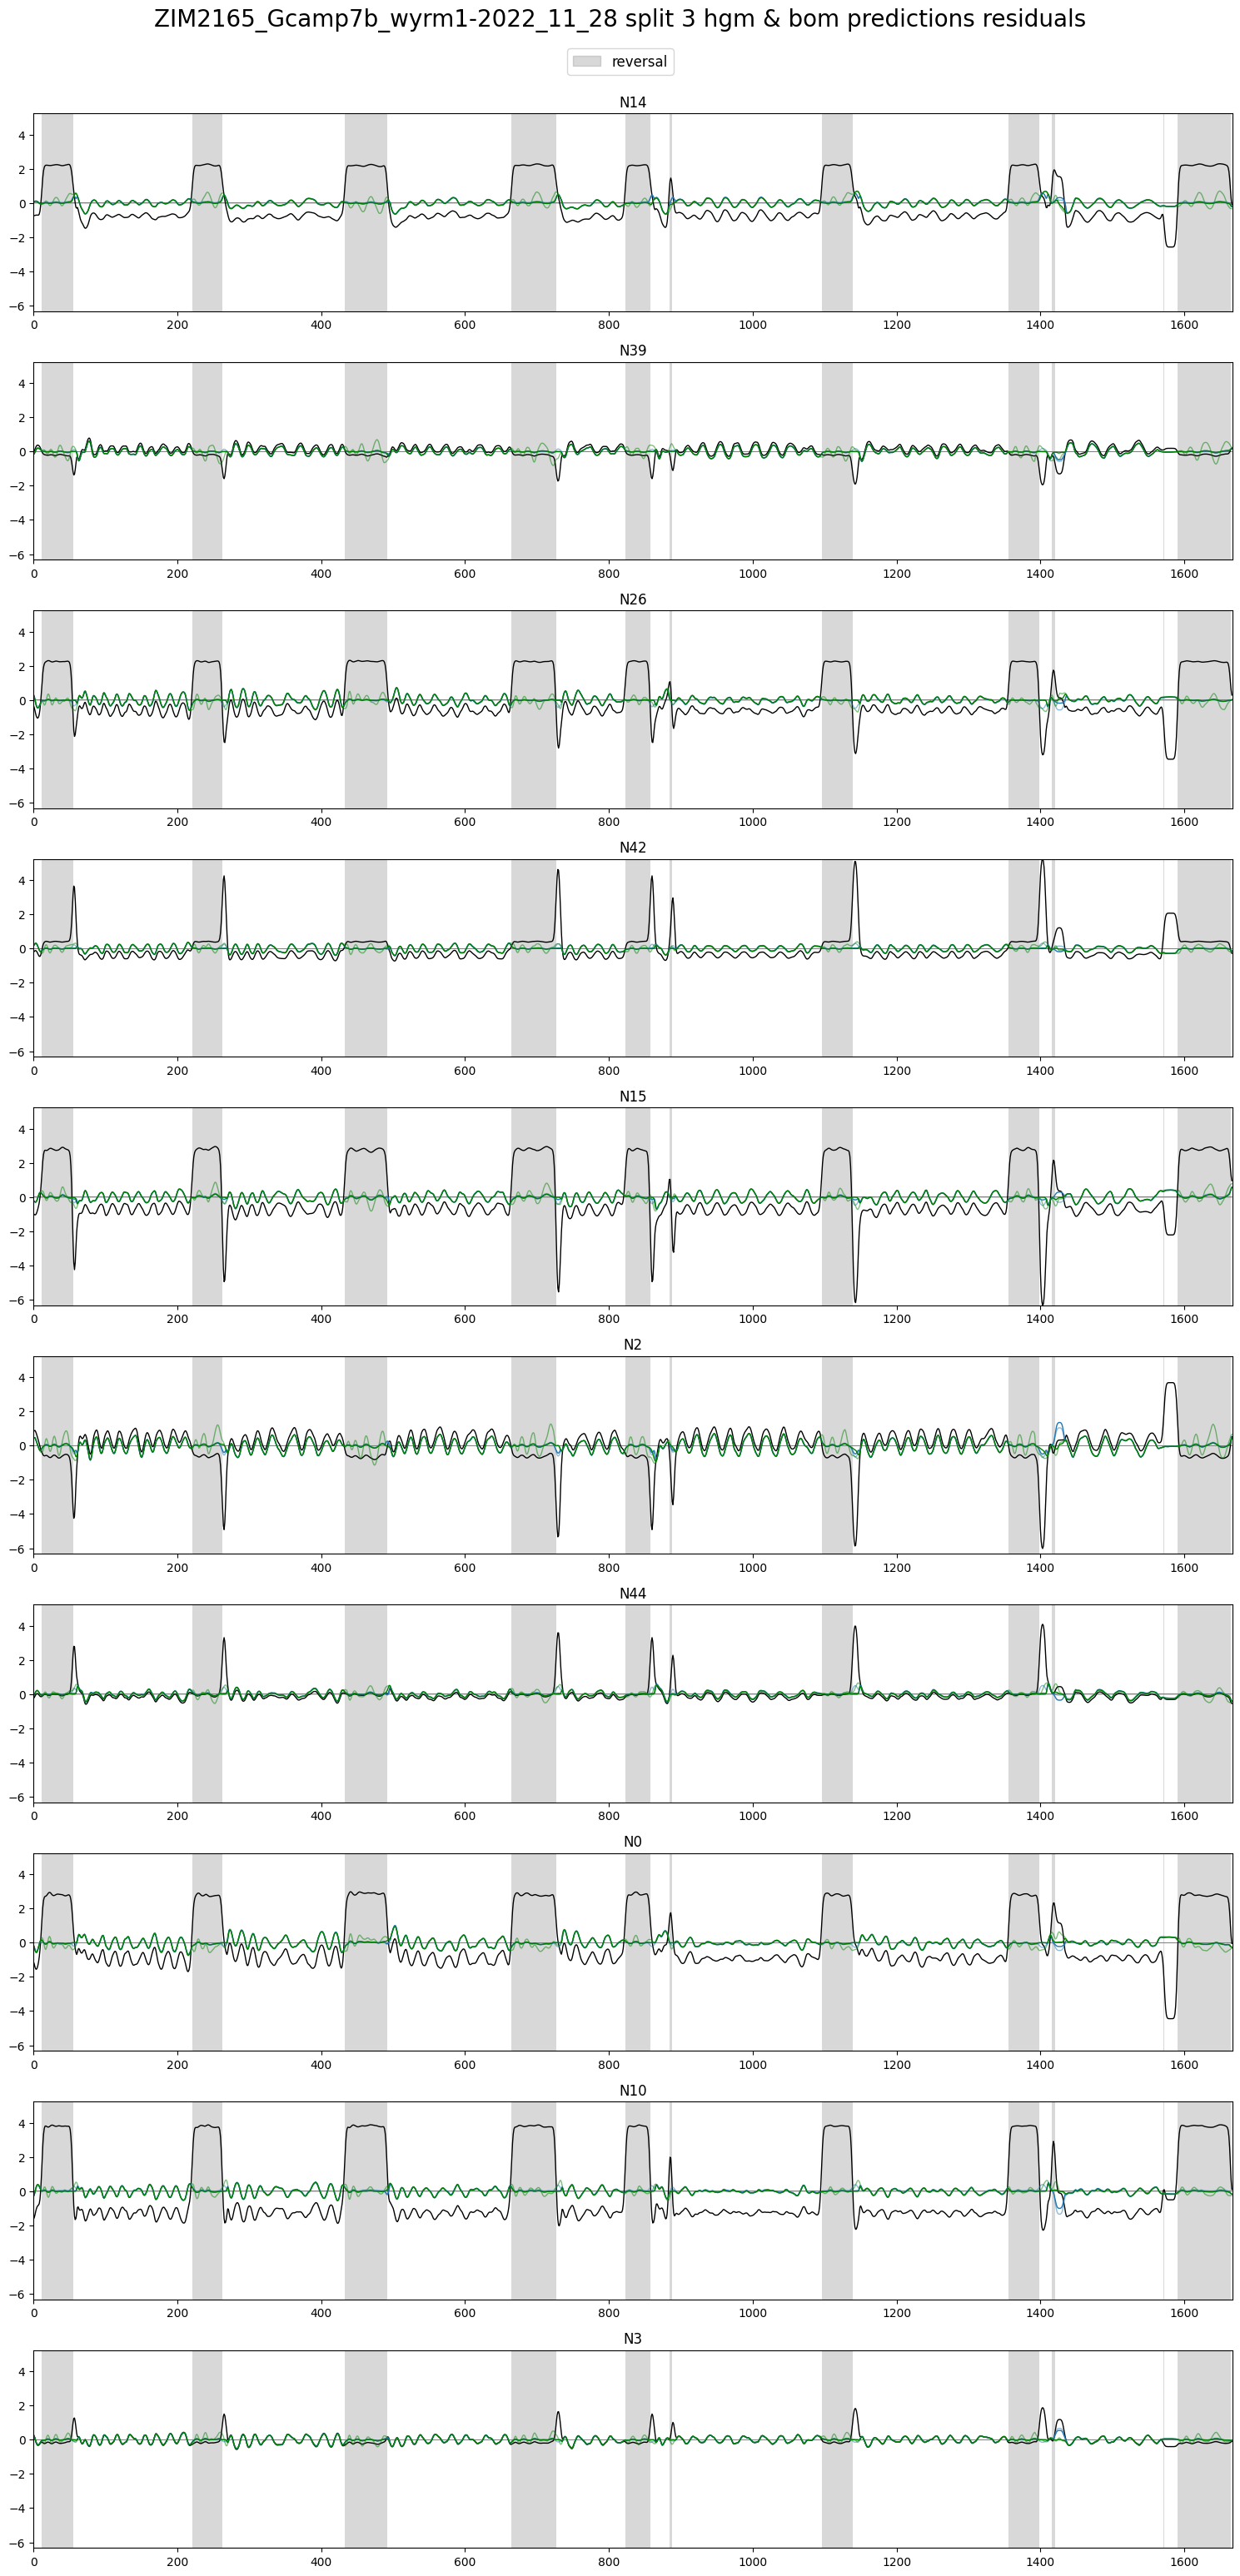

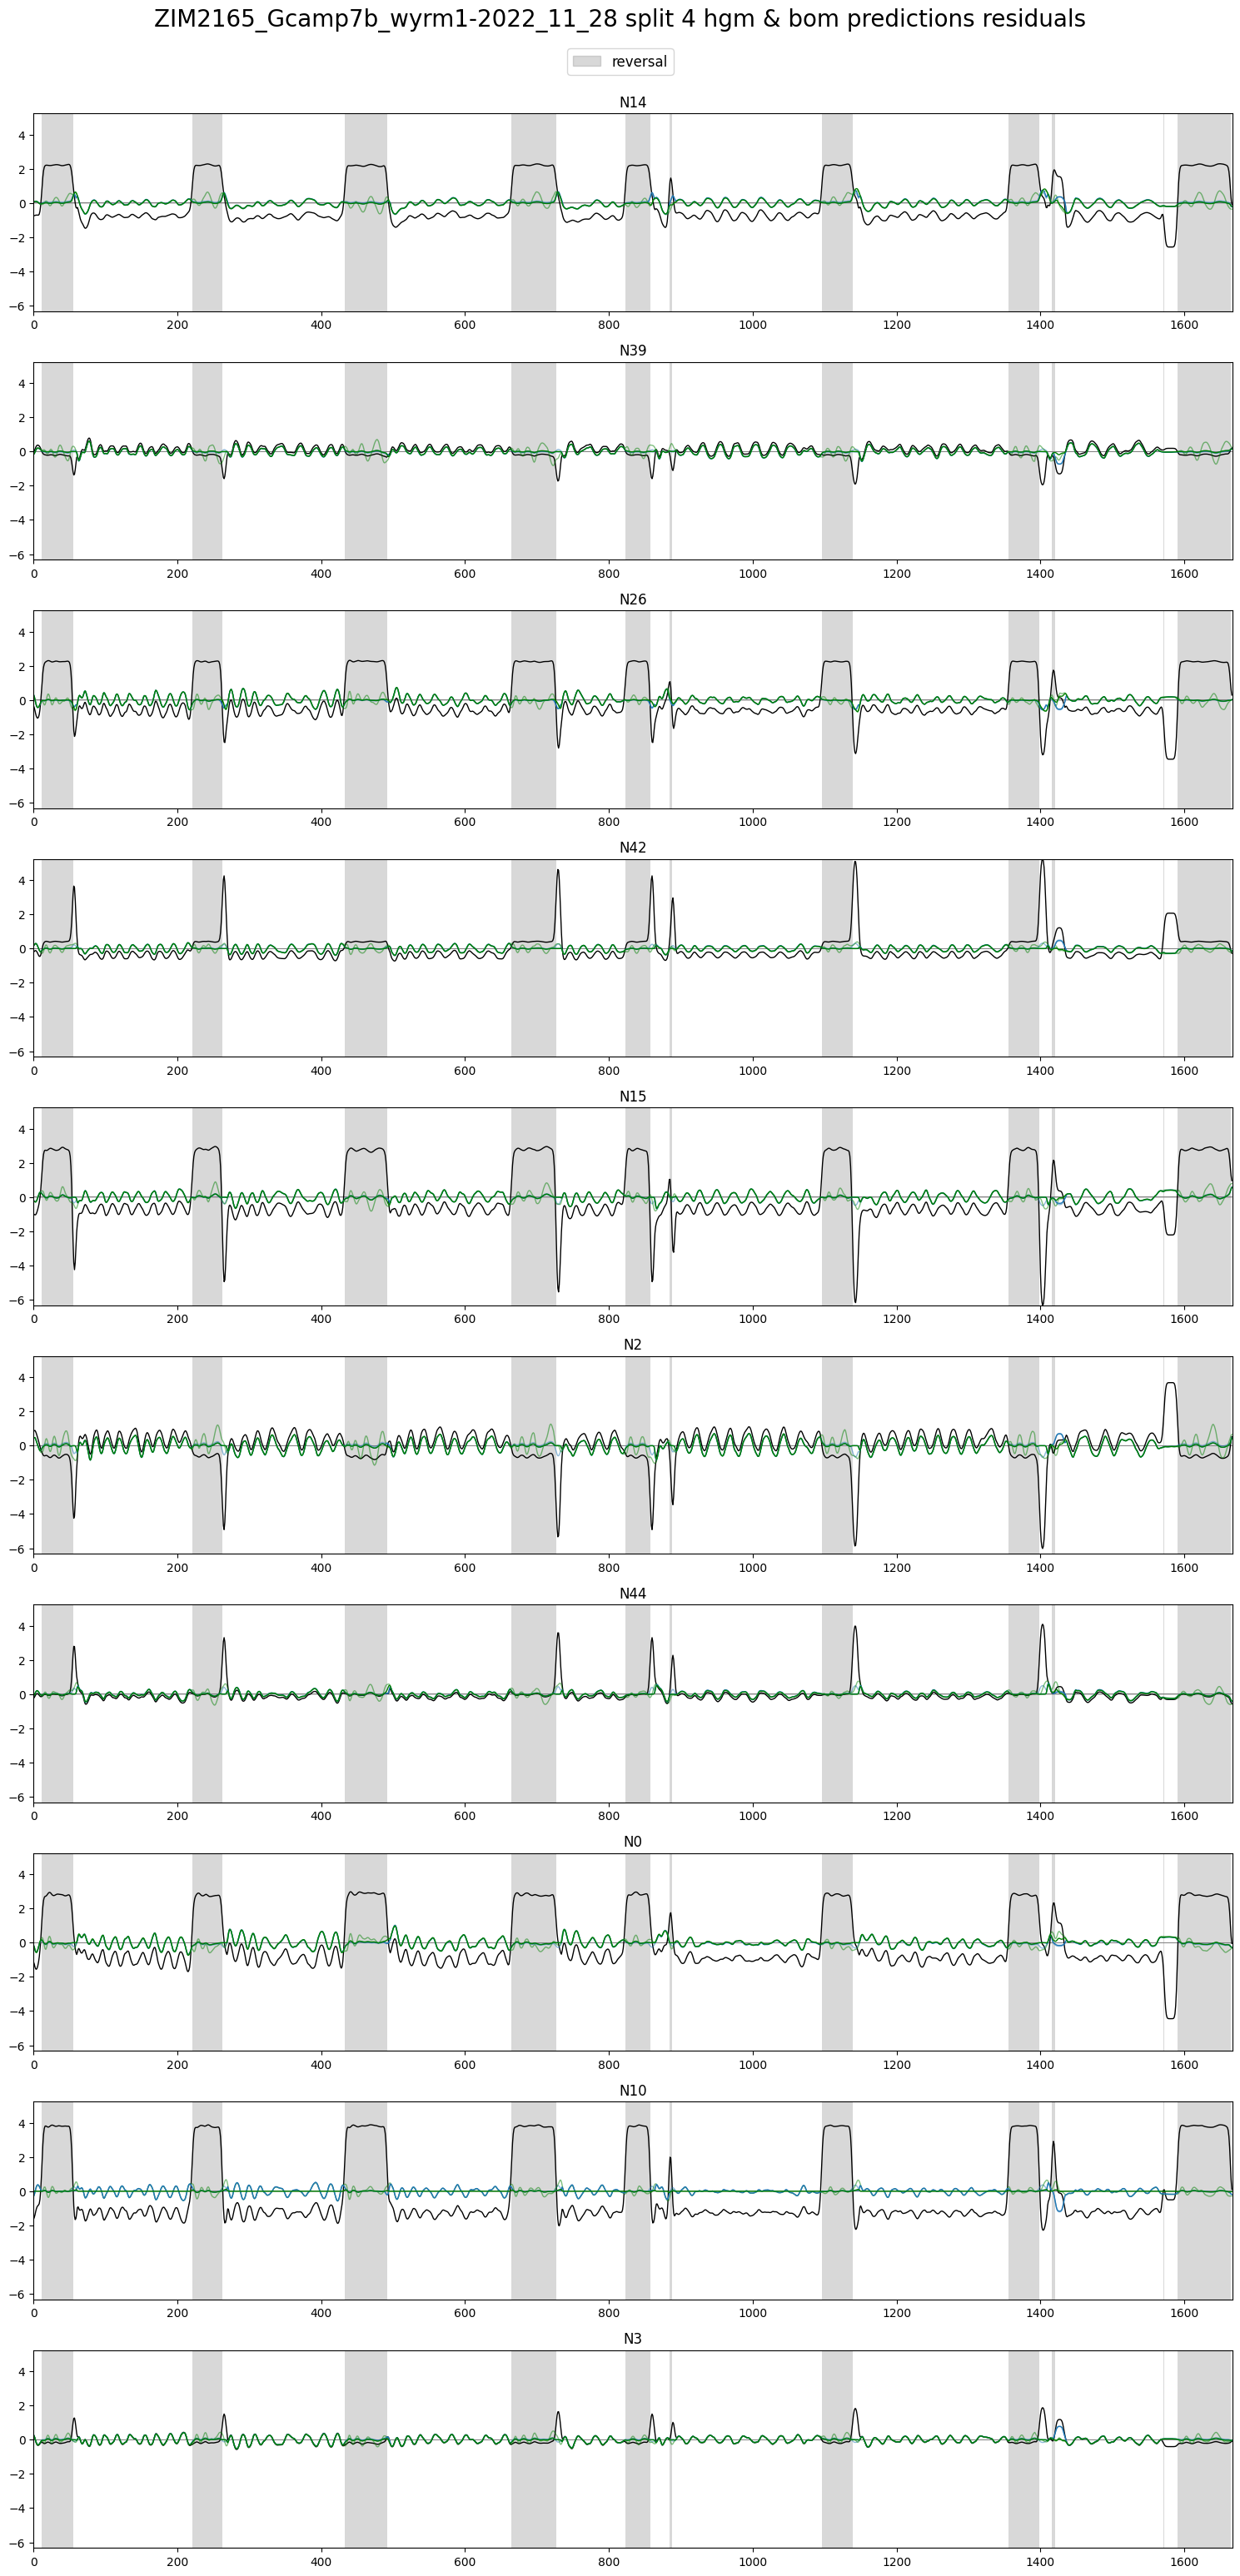

In [15]:
# max_x = 500
max_x = traces.values.shape[0]

for i in range(splits):
	plot_utils.plot_traces_splits_pairs(
		[hgm_res[i].loc[:max_x, neuron_labels],
		 hgm_pres[i].loc[:max_x, neuron_labels]],
		[bom_res[i].loc[:max_x, neuron_labels],
		 bom_pres[i].loc[:max_x, neuron_labels]],
		traces.loc[:max_x, neuron_labels],
		discrete_states.loc[:max_x, ['REV']], label='reversal',
		title=f'{filename} split {i} hgm & bom predictions residuals', ylimits=None, plots_per_row=1,
		save_path=None)  #../../out/plots/f'GCAMP_PRES_S{i}'